## Problem Statement

### Business Context

Business communities in the United States are facing high demand for human resources, but one of the constant challenges is identifying and attracting the right talent, which is perhaps the most important element in remaining competitive. Companies in the United States look for hard-working, talented, and qualified individuals both locally as well as abroad.

The Immigration and Nationality Act (INA) of the US permits foreign workers to come to the United States to work on either a temporary or permanent basis. The act also protects US workers against adverse impacts on their wages or working conditions by ensuring US employers' compliance with statutory requirements when they hire foreign workers to fill workforce shortages. The immigration programs are administered by the Office of Foreign Labor Certification (OFLC).

OFLC processes job certification applications for employers seeking to bring foreign workers into the United States and grants certifications in those cases where employers can demonstrate that there are not sufficient US workers available to perform the work at wages that meet or exceed the wage paid for the occupation in the area of intended employment.

### Objective

In FY 2016, the OFLC processed 775,979 employer applications for 1,699,957 positions for temporary and permanent labor certifications. This was a nine percent increase in the overall number of processed applications from the previous year. The process of reviewing every case is becoming a tedious task as the number of applicants is increasing every year.

The increasing number of applicants every year calls for a Machine Learning based solution that can help in shortlisting the candidates having higher chances of VISA approval. OFLC has hired the firm EasyVisa for data-driven solutions. You as a data  scientist at EasyVisa have to analyze the data provided and, with the help of a classification model:

* Facilitate the process of visa approvals.
* Recommend a suitable profile for the applicants for whom the visa should be certified or denied based on the drivers that significantly influence the case status.

### Data Description

The data contains the different attributes of employee and the employer. The detailed data dictionary is given below.

* case_id: ID of each visa application
* continent: Information of continent the employee
* education_of_employee: Information of education of the employee
* has_job_experience: Does the employee has any job experience? Y= Yes; N = No
* requires_job_training: Does the employee require any job training? Y = Yes; N = No
* no_of_employees: Number of employees in the employer's company
* yr_of_estab: Year in which the employer's company was established
* region_of_employment: Information of foreign worker's intended region of employment in the US.
* prevailing_wage:  Average wage paid to similarly employed workers in a specific occupation in the area of intended employment. The purpose of the prevailing wage is to ensure that the foreign worker is not underpaid compared to other workers offering the same or similar service in the same area of employment.
* unit_of_wage: Unit of prevailing wage. Values include Hourly, Weekly, Monthly, and Yearly.
* full_time_position: Is the position of work full-time? Y = Full Time Position; N = Part Time Position
* case_status:  Flag indicating if the Visa was certified or denied

### Importing necessary libraries

In [351]:
!pip install pandas==2.2.2 numpy==2.0.2 matplotlib==3.10.0 seaborn==0.13.2 scikit-learn==1.6.1 xgboost==2.1.4 -q

**Note:**

- After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab) and run all cells sequentially from the next cell.

- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [352]:
# Libraries to help with reading and manipulating data
import pandas as pd
import numpy as np

# Libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# To tune model, get different metric scores, and split data
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    recall_score,
    precision_score,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

# To be used for data scaling and one hot encoding
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder

# To impute missing values
from sklearn.impute import SimpleImputer
from sklearn import metrics

# To oversample and undersample data
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# To do hyperparameter tuning
from sklearn.model_selection import RandomizedSearchCV

# To define maximum number of columns to be displayed in a dataframe
pd.set_option("display.max_columns", None)

# To supress scientific notations for a dataframe
pd.set_option("display.float_format", lambda x: "%.3f" % x)

# To help with model building
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    AdaBoostClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
    BaggingClassifier,
)
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression

# To suppress scientific notations
pd.set_option("display.float_format", lambda x: "%.3f" % x)

# To supress warnings
import warnings

warnings.filterwarnings("ignore")

### Loading the dataset

In [353]:
# mounting the drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [354]:
# loading the dataset from drive
visaDataset = pd.read_csv("/content/drive/MyDrive/EasyVisa.csv")

## Data Overview

In [355]:
# let's create a copy of the data
df = visaDataset.copy()

### Displaying the first few rows of the dataset

In [356]:
# let's view the first 5 rows of the data
df.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.203,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.650,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.860,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.030,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.390,Year,Y,Certified


In [357]:
# let's view the last 5 rows of the data
df.tail()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
25475,EZYV25476,Asia,Bachelor's,Y,Y,2601,2008,South,77092.570,Year,Y,Certified
25476,EZYV25477,Asia,High School,Y,N,3274,2006,Northeast,279174.790,Year,Y,Certified
25477,EZYV25478,Asia,Master's,Y,N,1121,1910,South,146298.850,Year,N,Certified
25478,EZYV25479,Asia,Master's,Y,Y,1918,1887,West,86154.770,Year,Y,Certified
25479,EZYV25480,Asia,Bachelor's,Y,N,3195,1960,Midwest,70876.910,Year,Y,Certified


### Understand the shape of the dataset

In [358]:
# checking the number of rows and columns in the data
df.shape

(25480, 12)

* The dataset has 25480 rows and 12 columns

### Checking the data types of the columns for the dataset

In [359]:
# let's check the data types of the columns in the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25480 entries, 0 to 25479
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   case_id                25480 non-null  object 
 1   continent              25480 non-null  object 
 2   education_of_employee  25480 non-null  object 
 3   has_job_experience     25480 non-null  object 
 4   requires_job_training  25480 non-null  object 
 5   no_of_employees        25480 non-null  int64  
 6   yr_of_estab            25480 non-null  int64  
 7   region_of_employment   25480 non-null  object 
 8   prevailing_wage        25480 non-null  float64
 9   unit_of_wage           25480 non-null  object 
 10  full_time_position     25480 non-null  object 
 11  case_status            25480 non-null  object 
dtypes: float64(1), int64(2), object(9)
memory usage: 2.3+ MB


* Only 3 variables are numerical rest all are object types.
* all the columns have 25480 non-null values i.e. no columns have missing values.

### Checking for duplicate values

In [360]:
# let's check for duplicate values in the data
df.duplicated().sum()

np.int64(0)

* There's no duplicated values in the dataset.

### Checking for missing values

In [361]:
# check if any columns/variables has null values
df.isnull().sum()

,0
case_id,0
continent,0
education_of_employee,0
has_job_experience,0
requires_job_training,0
no_of_employees,0
yr_of_estab,0
region_of_employment,0
prevailing_wage,0
unit_of_wage,0


In [362]:
# let's check for missing values in the data
df.isna().sum()

,0
case_id,0
continent,0
education_of_employee,0
has_job_experience,0
requires_job_training,0
no_of_employees,0
yr_of_estab,0
region_of_employment,0
prevailing_wage,0
unit_of_wage,0


* None of the columns has any null values.
* No imputation needed.

In [363]:
# let's view the statistical summary of the numerical columns in the data
df.describe().T

,count,mean,std,min,25%,50%,75%,max
no_of_employees,25480.000,5667.043,22877.929,-26.000,1022.000,2109.000,3504.000,602069.000
yr_of_estab,25480.000,1979.410,42.367,1800.000,1976.000,1997.000,2005.000,2016.000
prevailing_wage,25480.000,74455.815,52815.942,2.137,34015.480,70308.210,107735.513,319210.270


**Observations**
* `no_of_employees:` There's 5667.04 average no of employees. Stardard deviation being 22,877.93 indicates high variability, some companies have very few employees, others have many. Min is -26, like;y an error as no. of employees can't be negative. Max is 6,002,069, seems like a very large company, possibly an outlier.
* `yr_of_estab:` Most companies were established around 1979. Oldest company was established in 1800, while the newest in 2016. Most being relatively modern (post-1970s).
* `prevailing_wage:` Varies widely, which could reflect different job roles, industries or regions. Mean $74,455.82. Minimum is 2.14 dollars (very low, possibly an error or specific context). 319,210.27 dollars is the highest wage in the dataset. 75% of employees are 107,735.51 dollars or less.

In [364]:
# confirm unique values in specific column/s like caseId with suspected unique values
df["case_id"].nunique()

25480

In [365]:
# case_id is unique for each candidate and might not add value to modeling
df.drop(["case_id"], axis=1, inplace=True)

- Removed the unnecessary case_id with unique values same as the size of the dataset, it had no impact in decision making process.

In [366]:
# create a copy of data to perform detailed EDA in the appendix section.
data = df.copy()

In [367]:
# Verify the copied new dataset
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25480 entries, 0 to 25479
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   continent              25480 non-null  object 
 1   education_of_employee  25480 non-null  object 
 2   has_job_experience     25480 non-null  object 
 3   requires_job_training  25480 non-null  object 
 4   no_of_employees        25480 non-null  int64  
 5   yr_of_estab            25480 non-null  int64  
 6   region_of_employment   25480 non-null  object 
 7   prevailing_wage        25480 non-null  float64
 8   unit_of_wage           25480 non-null  object 
 9   full_time_position     25480 non-null  object 
 10  case_status            25480 non-null  object 
dtypes: float64(1), int64(2), object(8)
memory usage: 2.1+ MB


## <a name='link2'>Exploratory Data Analysis (EDA) Summary</a>


### **Note**: The EDA section has been covered multiple times in the previous case studies. In this case study, we will mainly focus on the model building aspects. We will only be looking at the key observations from EDA. The detailed EDA can be found in the <a href = #link1>appendix section</a>.

**The below functions need to be defined to carry out the Exploratory Data Analysis.**

In [368]:
# function to plot a boxplot and a histogram along the same scale.


def histogram_boxplot(data, feature, figsize=(12, 7), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (12,7))
    kde: whether to the show density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a star will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins, palette="winter"
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

In [369]:
# function to create labeled barplots


def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with percentage at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    """

    total = len(data[feature])  # length of the column
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 1, 5))
    else:
        plt.figure(figsize=(n + 1, 5))

    plt.xticks(rotation=90, fontsize=15)
    ax = sns.countplot(
        data=data,
        x=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n].sort_values(),
    )

    for p in ax.patches:
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # percentage of each class of the category
        else:
            label = p.get_height()  # count of each level of the category

        x = p.get_x() + p.get_width() / 2  # width of the plot
        y = p.get_height()  # height of the plot

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # annotate the percentage

    plt.show()  # show the plot

In [370]:
# function to plot stacked bar chart


def stacked_barplot(data, predictor, target):
    """
    Print the category counts and plot a stacked bar chart

    data: dataframe
    predictor: independent variable
    target: target variable
    """
    count = data[predictor].nunique()
    sorter = data[target].value_counts().index[-1]
    tab1 = pd.crosstab(data[predictor], data[target], margins=True).sort_values(
        by=sorter, ascending=False
    )
    print(tab1)
    print("-" * 120)
    tab = pd.crosstab(data[predictor], data[target], normalize="index").sort_values(
        by=sorter, ascending=False
    )
    tab.plot(kind="bar", stacked=True, figsize=(count + 1, 5))
    plt.legend(
        loc="lower left", frameon=False,
    )
    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.show()

In [371]:
### Function to plot distributions


def distribution_plot_wrt_target(data, predictor, target):

    fig, axs = plt.subplots(2, 2, figsize=(12, 10))

    target_uniq = data[target].unique()

    axs[0, 0].set_title("Distribution of target for target=" + str(target_uniq[0]))
    sns.histplot(
        data=data[data[target] == target_uniq[0]],
        x=predictor,
        kde=True,
        ax=axs[0, 0],
        color="teal",
    )
    axs[0, 0].set_xticklabels(axs[0, 0].get_xticklabels(), rotation=90)

    axs[0, 1].set_title("Distribution of target for target=" + str(target_uniq[1]))
    sns.histplot(
        data=data[data[target] == target_uniq[1]],
        x=predictor,
        kde=True,
        ax=axs[0, 1],
        color="orange",
    )
    axs[0, 1].set_xticklabels(axs[0, 0].get_xticklabels(), rotation=90)

    axs[1, 0].set_title("Boxplot w.r.t target")
    sns.boxplot(data=data, x=target, y=predictor, ax=axs[1, 0], palette="gist_rainbow")

    axs[1, 1].set_title("Boxplot (without outliers) w.r.t target")
    sns.boxplot(
        data=data,
        x=target,
        y=predictor,
        ax=axs[1, 1],
        showfliers=False,
        palette="gist_rainbow",
    )

    plt.tight_layout()
    plt.show()

<a id='eda'></a>
### <a id='link'>Summary of EDA</a>

* The dataset has 25480 rows and 12 columns
* Only 3 variables are numerical rest all are object types.
* None of the columns have missing values.

**Data Cleaning**
* Already dropped "case_id" as "case_id" is unique for each candidate and might not add value to modeling.

#### Observations from EDA

**Univariate Analysis**

- continent: Asia has the largest number of cases (both Denied and Certified) and the most variability in target values, as seen in the histograms and boxplots. Europe (80.77%) and Africa (80%) have the highest certification rates. North America (64.86%) and Asia (65.15%) have the lowest certification rates.
- education_of_employee: Bachelor's is most common, followed by Master's, High School, and Doctorate. Doctorate holders have the highest certification rate at 88.46%, followed by Master's (74.27%) and Bachelor's (67.34%).
- has_job_experience: 1job experience have a significantly higher certification rate (74.68%) compared to those without (54.76%).
- requires_job_training: Job training (Y) have a slightly higher certification rate (69.84%) compared to those who do not (65.35%).
- no_of_employees: About 75% of cases in both groups involve companies with fewer than 5,000 employees, and outliers above 100,000 employees are equally rare in both groups.
- yr_of_estab: Ranges fromm yr 1800 to over yr 2000.
- region_of_employment: Northeast leads with 7,195 cases (28.2%), followed by South (7,018, 27.5%), West (6,586, 25.8%), Midwest (4,302, 16.9%), and Island (379, 1.5%).
- prevailing_wage: Ranges from 2.14 to 319,210.27 (mean ~74,456, median ~70,310), with 50% of wages below 70,310 and 10% above 150,000, showing a right-skewed distribution.
- unit_of_wage: Year is most common with 22,962 cases (~90.0%), followed by Hour (2,157, 8.5%), Week (271, 1.1%), and Month (89), heavily skewed toward yearly wages.
- full_time_position: 22,773 cases are full-time (~89.3%), while 2,707 are not (10.7%), indicating most positions are full-time.
case_status: Certified cases are 17,018 (66.8%), while Denied are 8,462 (33.2%), confirming the known class imbalance (~67:33).

**Bivariate Analysis**

* There is no stronger correlation than max of about ~20% correlationship of couple of variables like education_of_employee for Master's degree and hourly unit_of_wage.
* Among independent variables, previaling_wage and yearly unit_of_wage has the highest correlation of about ~40%.
* Most of the other variables have either very low or negative relaionship amont themselves and with the target case_status.

## Data Preprocessing

### Feature Engineering

In [372]:
# list of all categorical variables
cat_col = df.columns

# printing the number of occurrences of each unique value in each categorical column
for column in cat_col:
    print(df[column].value_counts(normalize=True))
    print("-" * 50)

continent
Asia            0.662
Europe          0.146
North America   0.129
South America   0.033
Africa          0.022
Oceania         0.008
Name: proportion, dtype: float64
--------------------------------------------------
education_of_employee
Bachelor's    0.402
Master's      0.378
High School   0.134
Doctorate     0.086
Name: proportion, dtype: float64
--------------------------------------------------
has_job_experience
Y   0.581
N   0.419
Name: proportion, dtype: float64
--------------------------------------------------
requires_job_training
N   0.884
Y   0.116
Name: proportion, dtype: float64
--------------------------------------------------
no_of_employees
183     0.001
854     0.001
724     0.001
1476    0.001
766     0.001
         ... 
3711    0.000
16399   0.000
4600    0.000
33210   0.000
4830    0.000
Name: proportion, Length: 7105, dtype: float64
--------------------------------------------------
yr_of_estab
1998   0.045
2005   0.041
2001   0.040
2007   0.039
1999   

In [373]:
# Analyze years of establishment
df["yr_of_estab"].unique()

array([2007, 2002, 2008, 1897, 2005, 2012, 1994, 1924, 1995, 2004, 1963,
       2006, 1987, 1991, 2001, 1972, 2013, 1968, 1884, 1981, 1997, 2009,
       1998, 1880, 2000, 2010, 1965, 1909, 2011, 1989, 1933, 1960, 2003,
       1976, 1996, 1847, 1935, 1890, 1999, 1838, 1947, 1939, 1970, 1977,
       1982, 1943, 1956, 1864, 1974, 1985, 1984, 1971, 1913, 1969, 1818,
       1839, 1914, 1988, 1944, 1855, 1975, 1966, 1801, 1920, 1925, 1993,
       1992, 1979, 1986, 1931, 1962, 1954, 1868, 1859, 1946, 1950, 1869,
       1917, 2014, 1980, 1896, 1949, 1843, 1850, 1906, 1961, 1951, 1958,
       1912, 1983, 1948, 1945, 1978, 1898, 1923, 1911, 1851, 1865, 1849,
       1872, 1967, 1926, 1873, 1848, 2015, 1889, 1876, 1852, 1938, 1973,
       1959, 1927, 1990, 1930, 1922, 1940, 1878, 1934, 1834, 1928, 1800,
       1861, 1952, 1846, 1885, 1907, 1817, 1841, 1821, 1953, 1888, 1916,
       1886, 2016, 1932, 1915, 1937, 1866, 1919, 1921, 1910, 1854, 1875,
       1904, 1879, 1942, 1964, 1899, 1900, 1837, 18

In [374]:
# Check if there's enough unique elemnts to bucket
df['yr_of_estab'].nunique()

199

* There are 199 unique years of establishments in data, we can reduce the levels by grouping them into 4 major categories:
  * 19th Century - with companies established years before 1900
  * 20th Century - with companies established years between 1900 - 2000
  * 21st Century - with companies established years before 2000 - 2100

We will bin the data after splitting into train/test/val to avoid data leakage.

In [375]:
# Discretize variable into equal-sized buckets based on quantiles
df["era_of_estab"] = ((df["yr_of_estab"]) // 100 + 1).astype(str) + ' Century'

* 199 unique values have been binned into 3 categories.

In [376]:
# Verify Eras of establishment
df["era_of_estab"].value_counts()

,count
era_of_estab,
20 Century,12903
21 Century,10469
19 Century,2108


In [377]:
# Drop the coverted column years of establishment
df.drop(["yr_of_estab"], axis=1, inplace=True)

In [378]:
# Get the total no. of records w/ negatives values in no. of employees column
df.loc[df['no_of_employees'] < 0].shape

(33, 11)

In [379]:
# Check the dataset with negatives values in no. of employees column
df.loc[df['no_of_employees'] < 0]

,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status,era_of_estab
245,Europe,Master's,N,N,-25,Northeast,39452.990,Year,Y,Certified,20 Century
378,Asia,Bachelor's,N,Y,-11,Northeast,32506.140,Year,Y,Denied,21 Century
832,South America,Master's,Y,N,-17,South,129701.940,Year,Y,Certified,21 Century
2918,Asia,Master's,Y,N,-26,Midwest,112799.460,Year,Y,Certified,21 Century
6439,Asia,Bachelor's,N,N,-14,South,103.970,Hour,Y,Denied,21 Century
6634,Asia,Bachelor's,Y,N,-26,West,5247.320,Year,Y,Denied,20 Century
7224,Europe,Doctorate,N,N,-25,Midwest,141435.950,Year,Y,Certified,20 Century
7281,Asia,High School,N,N,-14,Midwest,58488.500,Year,Y,Denied,21 Century
7318,Asia,Bachelor's,Y,Y,-26,South,115005.610,Year,Y,Certified,21 Century
7761,Asia,Master's,N,N,-11,Midwest,38457.510,Year,Y,Certified,21 Century


In [380]:
# Convert negative values in the absolute positive
df['no_of_employees'] = df['no_of_employees'].abs()

- Divided years of establishment into bins of centuries (era_of_estab) and converted number of employees column to have only positive values

In [381]:
# Create a copy of a dataset post feature engineering
data1 = df.copy()

#### Let's check the count of each unique category in each of the categorical variables

In [382]:
# Unique continents
df['continent'].unique()

array(['Asia', 'Africa', 'North America', 'Europe', 'South America',
       'Oceania'], dtype=object)

In [383]:
# Unique Education categories
df['education_of_employee'].unique()

array(['High School', "Master's", "Bachelor's", 'Doctorate'], dtype=object)

In [384]:
# Unique values for has job experience feature
df['has_job_experience'].unique()

array(['N', 'Y'], dtype=object)

In [385]:
# Unique values for requires job training feature
df['requires_job_training'].unique()

array(['N', 'Y'], dtype=object)

In [386]:
# Unique regions of employment
df['region_of_employment'].unique()

array(['West', 'Northeast', 'South', 'Midwest', 'Island'], dtype=object)

In [387]:
# Unique units of wage
df['unit_of_wage'].unique()

array(['Hour', 'Year', 'Week', 'Month'], dtype=object)

In [388]:
# Unique values for full time position feature
df['full_time_position'].unique()

array(['Y', 'N'], dtype=object)

In [389]:
# Unique eras of establishment
df['era_of_estab'].unique()

array(['21 Century', '19 Century', '20 Century'], dtype=object)

- All other features above seems to have pretty clean unique values

In [390]:
data1.head()

,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status,era_of_estab
0,Asia,High School,N,N,14513,West,592.203,Hour,Y,Denied,21 Century
1,Asia,Master's,Y,N,2412,Northeast,83425.650,Year,Y,Certified,21 Century
2,Asia,Bachelor's,N,Y,44444,West,122996.860,Year,Y,Denied,21 Century
3,Asia,Bachelor's,N,N,98,West,83434.030,Year,Y,Denied,19 Century
4,Africa,Master's,Y,N,1082,South,149907.390,Year,Y,Certified,21 Century


### Outlier Check

- Let's check for outliers in the data.

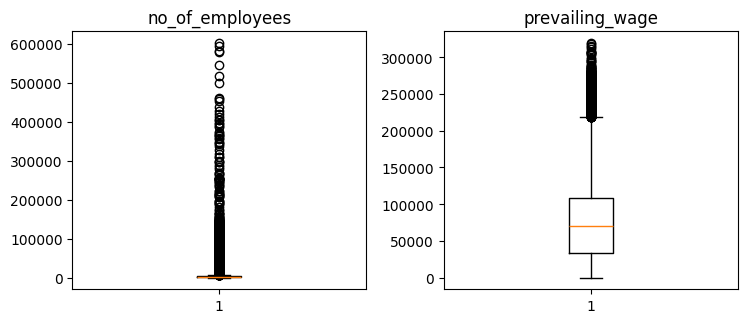

In [391]:
# outlier detection for numerical variables using boxplot
numeric_columns = data1.select_dtypes(include=np.number).columns.tolist()

plt.figure(figsize=(15, 12))

for i, variable in enumerate(numeric_columns):
    plt.subplot(4, 4, i + 1)
    plt.boxplot(data1[variable], whis=1.5)
    plt.tight_layout()
    plt.title(variable)

plt.show()

- Number of Employees: The data is heavily right skewed, with a median near 0 and a few extreme outliers reaching over 60,000. Most companies have very few employees, but a small number have significantly larger workforces.
- Prevailing Wage: The data is also right skewed, with a median around 7,000 and outliers extending over 300,000. Most wages cluster at the lower end, but a few are exceptionally high.

### Data Preparation for Modeling

### Creating Dummy Variables

In [392]:
X = data1.drop(["case_status"], axis=1) # Get all the independent columns
y = data1["case_status"].apply(lambda x: 1 if x == "Certified" else 0) # Get the dependent variable after converting to binary values

In [393]:
X = pd.get_dummies(X, drop_first=False) # Get dummies for independent columns

In [394]:
# Reduce binary columns by merging into one with int datatype
X['has_job_experience'] = X['has_job_experience_Y'].astype(int)
X['requires_job_training'] = X['requires_job_training_Y'].astype(int)
X['full_time_position'] = X['full_time_position_Y'].astype(int)

In [395]:
# Update X after dropping unnecessary binary columns
X = X.drop(columns=['has_job_experience_Y', 'has_job_experience_N', 'requires_job_training_Y', 'requires_job_training_N', 'full_time_position_Y', 'full_time_position_N'], axis=1)

In [396]:
# Convert the rest boolean columns into int type columns
bool_cols = X.select_dtypes(include=['bool']).columns
X[bool_cols] = X[bool_cols].astype(int)

- Prepared data by putting dependent variables/predictors into y and independent variables into X bucket
- Created dummies for predictors
- Reduced binary columns into suitable boolean column which then were converted to int type column.
- Converted boolean type columns post dummies creation into int as well to keep it binary.

In [397]:
# Verify all the columns now have numerical datatype
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25480 entries, 0 to 25479
Data columns (total 27 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   no_of_employees                    25480 non-null  int64  
 1   prevailing_wage                    25480 non-null  float64
 2   continent_Africa                   25480 non-null  int64  
 3   continent_Asia                     25480 non-null  int64  
 4   continent_Europe                   25480 non-null  int64  
 5   continent_North America            25480 non-null  int64  
 6   continent_Oceania                  25480 non-null  int64  
 7   continent_South America            25480 non-null  int64  
 8   education_of_employee_Bachelor's   25480 non-null  int64  
 9   education_of_employee_Doctorate    25480 non-null  int64  
 10  education_of_employee_High School  25480 non-null  int64  
 11  education_of_employee_Master's     25480 non-null  int

In [398]:
# Splitting data into training, validation and test set:
# first we split data into 2 parts, say temporary and test

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1, stratify=y
)

# then we split the temporary set into train and validation

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=1, stratify=y_temp
)

print(X_train.shape, X_val.shape, X_test.shape)

(15288, 27) (5096, 27) (5096, 27)


- The splitting code is well-structured, achieving a 60:20:20 train:validation:test split (15,288:5096:5096 rows), with stratification ensuring balanced class distributions (~67:33) in all sets, critical for this imbalanced dataset.
- The shapes (15288, 27), (5096, 27), and (5096, 27) align with expectations, and random_state=1 ensures reproducibility.

In [399]:
# Verify case_status proportions on all three datasets
print("Proportion on train set\n", y.value_counts(1))
print("Proportion on val set\n", y_val.value_counts(1))
print("Proportion on test set\n", y_test.value_counts(1))

Proportion on train set
 case_status
1   0.668
0   0.332
Name: proportion, dtype: float64
Proportion on val set
 case_status
1   0.668
0   0.332
Name: proportion, dtype: float64
Proportion on test set
 case_status
1   0.668
0   0.332
Name: proportion, dtype: float64


- Made sure all three train, val and test sets have equal proportions.

In [400]:
# Verify number of rows distributes across all the datasets
print("Number of rows in train data =", X_train.shape[0])
print("Number of rows in validation data =", X_val.shape[0])
print("Number of rows in test data =", X_test.shape[0])

Number of rows in train data = 15288
Number of rows in validation data = 5096
Number of rows in test data = 5096


# Model Building

## Model evaluation criterion

**Model can make wrong predictions as:**
1. Predicting employee is eligibile for visa approval but in reality, the enrollee is not leligible - Bringing aboard inadequate resources
2. Predicting an employee is not eligible for a visa approval but the employee is eligible  - Loss of good talent

**Which case is more important?**
* Predicting an enrollee is not eligible for a visa approval but the employee is actually is eligible i.e. denying visa to potential candidate as the candidate will not have certified visa status to work for the company by when he/she should be targeted.

**How to reduce this loss i.e need to reduce False Negatives?**
* Company would want Recall to be maximized, greater the Recall lesser the chances of false negatives.

**How to reduce this loss i.e need to reduce False Positives?**
* Company would want Precision to be maximized, greater the Precision lesser the chances of false positives.

**Let's define a function to output different metrics (including recall) on the train and test set and a function to show confusion matrix so that we do not have to use the same code repetitively while evaluating models.**

In [401]:
# defining a function to compute different metrics to check performance of a classification model built using sklearn
def model_performance_classification_sklearn(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred)  # to compute Recall
    precision = precision_score(target, pred)  # to compute Precision
    f1 = f1_score(target, pred)  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1": f1,},
        index=[0],
    )

    return df_perf

In [402]:
# defining a function to plot confusion matrix with percentages of a classification model built using sklearn
def confusion_matrix_sklearn(model, predictors, target):
    """
    To plot the confusion_matrix with percentages

    model: classifier
    predictors: independent variables
    target: dependent variable
    """
    y_pred = model.predict(predictors)
    cm = confusion_matrix(target, y_pred)
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")

## Initial Model Building

#### Defining scorer to be used for cross-validation and hyperparameter tuning

In [403]:
from sklearn.metrics import make_scorer, f1_score # Importing the necessary function to define scorer
scorer = make_scorer(f1_score) # Defining the scoring metric using the make_scorer function

- We are going with f1_score as scorer metric considering how useful it'll be with hypertuning.

### Model Building - Original Data

In [404]:
models = []  # Empty list to store all the models

# Appending models into the list
models.append(("Bagging", BaggingClassifier(estimator=DecisionTreeClassifier(random_state=1, class_weight='balanced'), random_state=1)))
models.append(("Random forest", RandomForestClassifier(random_state=1, class_weight='balanced')))
models.append(("GBM", GradientBoostingClassifier(random_state=1)))
models.append(("Adaboost", AdaBoostClassifier(random_state=1, estimator=DecisionTreeClassifier(random_state=1, class_weight='balanced', max_depth=1))))
models.append(("dtree", DecisionTreeClassifier(random_state=1, class_weight='balanced')))
models.append(("XGBoost", XGBClassifier(random_state=1, eval_metric="logloss")))

results1 = []  # Empty list to store all model's CV scores
names = []  # Empty list to store name of the models


# loop through all models to get the mean cross validated score
print("\n" "Cross-Validation performance on training dataset:" "\n")

for name, model in models:
    kfold = StratifiedKFold(
        n_splits=5, shuffle=True, random_state=1
    )  # Number of splits is 5
    cv_result = cross_val_score(
        estimator=model, X=X_train, y=y_train, scoring=scorer, cv=kfold
    )
    results1.append(cv_result)
    names.append(name)
    print("{}: {}".format(name, cv_result.mean()))

print("\n" "Validation Performance:" "\n")

for name, model in models:
    model.fit(X_train, y_train) # Fit the model on X_train and y_train
    scores = f1_score(y_val, model.predict(X_val))
    print("{}: {}".format(name, scores))


Cross-Validation performance on training dataset:

Bagging: 0.776701198931388
Random forest: 0.7950870969814812
GBM: 0.8228041947810766
Adaboost: 0.8108994681982946
dtree: 0.7473181682576296
XGBoost: 0.8098222601468994

Validation Performance:

Bagging: 0.7733372228704785
Random forest: 0.7933087609866742
GBM: 0.8255117671633477
Adaboost: 0.8145016653856009
dtree: 0.7435141509433962
XGBoost: 0.8106219426974144


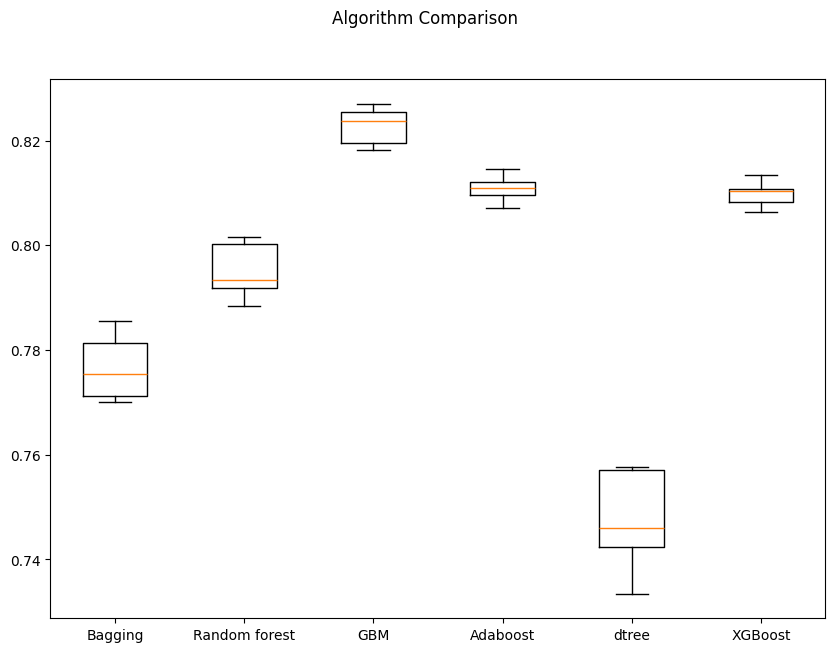

In [405]:
# Plotting boxplots for CV scores of all models defined above
fig = plt.figure(figsize=(10, 7))

fig.suptitle("Algorithm Comparison")
ax = fig.add_subplot(111)

plt.boxplot(results1)
ax.set_xticklabels(names)

plt.show()

- Gradient Boosting has the best performance followed by AdaBoost model and then follows XGBoost as per the validation performance on original dataset.

### Model Building - Oversampled Data

In [406]:
print("Before OverSampling, counts of label '1': {}".format(sum(y_train == 1)))
print("Before OverSampling, counts of label '0': {} \n".format(sum(y_train == 0)))

# Synthetic Minority Over Sampling Technique
sm = SMOTE(sampling_strategy=1, k_neighbors=5, random_state=1) ## Set the k-nearest neighbors and sampling strategy
X_train_over, y_train_over = sm.fit_resample(X_train, y_train)

print("After OverSampling, counts of label '1': {}".format(sum(y_train_over == 1)))
print("After OverSampling, counts of label '0': {} \n".format(sum(y_train_over == 0)))

print("After OverSampling, the shape of train_X: {}".format(X_train_over.shape))
print("After OverSampling, the shape of train_y: {} \n".format(y_train_over.shape))

Before OverSampling, counts of label '1': 10210
Before OverSampling, counts of label '0': 5078 

After OverSampling, counts of label '1': 10210
After OverSampling, counts of label '0': 10210 

After OverSampling, the shape of train_X: (20420, 27)
After OverSampling, the shape of train_y: (20420,) 



In [407]:
models = []  # Empty list to store all the models
from sklearn.metrics import make_scorer, f1_score # Importing the necessary function to define scorer
scorer = make_scorer(f1_score) # Defining the scoring metric using the make_scorer function

# Appending models into the list
models.append(("Bagging", BaggingClassifier(estimator=DecisionTreeClassifier(random_state=1, class_weight='balanced'), random_state=1)))
models.append(("Random forest", RandomForestClassifier(random_state=1, class_weight='balanced')))
models.append(("GBM", GradientBoostingClassifier(random_state=1)))
models.append(("Adaboost", AdaBoostClassifier(random_state=1, estimator=DecisionTreeClassifier(random_state=1, class_weight='balanced', max_depth=1))))
models.append(("dtree", DecisionTreeClassifier(random_state=1, class_weight='balanced')))
models.append(("XGBoost", XGBClassifier(random_state=1, eval_metric="logloss")))

results1 = []  # Empty list to store all model's CV scores
names = []  # Empty list to store name of the models


# loop through all models to get the mean cross validated score
print("\n" "Cross-Validation performance on training dataset:" "\n")

for name, model in models:
    kfold = StratifiedKFold(
        n_splits=5, shuffle=True, random_state=1
    )  # Number of splits is 5
    cv_result = cross_val_score(
        estimator=model, X=X_train_over, y=y_train_over,scoring = scorer, cv=kfold
    )
    results1.append(cv_result)
    names.append(name)
    print("{}: {}".format(name, cv_result.mean()))

print("\n" "Validation Performance:" "\n")

for name, model in models:
    model.fit(X_train_over, y_train_over) # Fit the model on the oversampled data
    scores = f1_score(y_val, model.predict(X_val)) ## Define the metric function name
    print("{}: {}".format(name, scores))


Cross-Validation performance on training dataset:

Bagging: 0.7685124185044627
Random forest: 0.7900317761940354
GBM: 0.8126675703263075
Adaboost: 0.7832524155597206
dtree: 0.7341120372240647
XGBoost: 0.8070532838493764

Validation Performance:

Bagging: 0.7642517814726841
Random forest: 0.7884921208616452
GBM: 0.8153779945488452
Adaboost: 0.7911802853437094
dtree: 0.7447411606743249
XGBoost: 0.8111079785734423


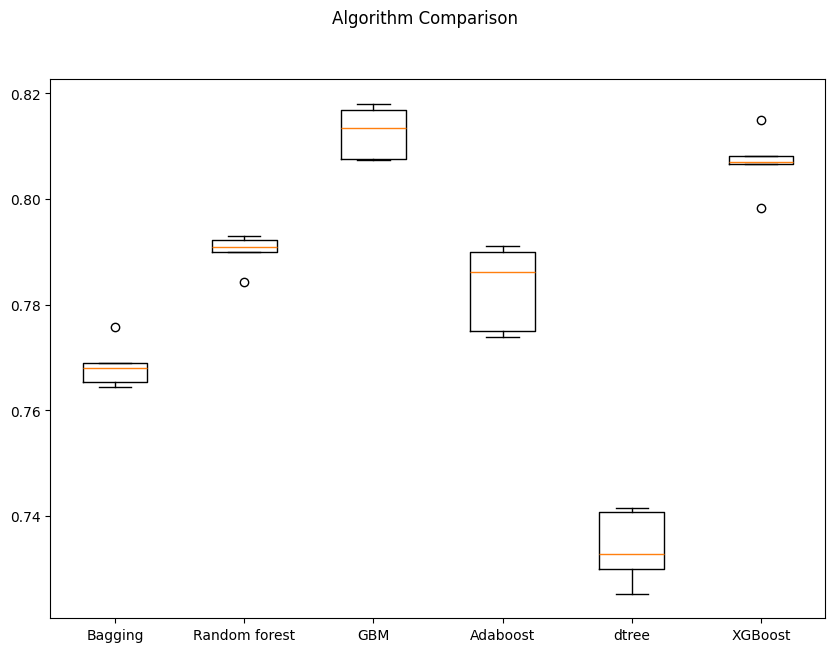

In [408]:
# Plotting boxplots for CV scores of all models defined above
fig = plt.figure(figsize=(10, 7))

fig.suptitle("Algorithm Comparison")
ax = fig.add_subplot(111)

plt.boxplot(results1)
ax.set_xticklabels(names)

plt.show()

- Gradient Boost has the best performance on validation followed by XGBoost and then AdaBoost on oversampled dataset.


### Model Building - Undersampled Data

In [279]:
rus = RandomUnderSampler(random_state=1, sampling_strategy=1)
X_train_un, y_train_un = rus.fit_resample(X_train, y_train)

print("Before UnderSampling, counts of label '1': {}".format(sum(y_train == 1)))
print("Before UnderSampling, counts of label '0': {} \n".format(sum(y_train == 0)))

print("After UnderSampling, counts of label '1': {}".format(sum(y_train_un == 1)))
print("After UnderSampling, counts of label '0': {} \n".format(sum(y_train_un == 0)))

print("After UnderSampling, the shape of train_X: {}".format(X_train_un.shape))
print("After UnderSampling, the shape of train_y: {} \n".format(y_train_un.shape))

Before UnderSampling, counts of label '1': 10210
Before UnderSampling, counts of label '0': 5078 

After UnderSampling, counts of label '1': 5078
After UnderSampling, counts of label '0': 5078 

After UnderSampling, the shape of train_X: (10156, 27)
After UnderSampling, the shape of train_y: (10156,) 



In [280]:
models = []  # Empty list to store all the models

# Appending models into the list
models.append(("Bagging", BaggingClassifier(estimator=DecisionTreeClassifier(random_state=1, class_weight='balanced'), random_state=1)))
models.append(("Random forest", RandomForestClassifier(random_state=1, class_weight='balanced')))
models.append(("GBM", GradientBoostingClassifier(random_state=1)))
models.append(("Adaboost", AdaBoostClassifier(random_state=1, estimator=DecisionTreeClassifier(random_state=1, class_weight='balanced', max_depth=1))))
models.append(("dtree", DecisionTreeClassifier(random_state=1, class_weight='balanced')))
models.append(("XGBoost", XGBClassifier(random_state=1, eval_metric="logloss")))

results1 = []  # Empty list to store all model's CV scores
names = []  # Empty list to store name of the models


# loop through all models to get the mean cross validated score
print("\n" "Cross-Validation performance on training dataset:" "\n")

for name, model in models:
    kfold = StratifiedKFold(
        n_splits=5, shuffle=True, random_state=1
    )
    cv_result = cross_val_score(
        estimator=model, X=X_train_un, y=y_train_un,scoring = scorer, cv=kfold,n_jobs =-1
    )
    results1.append(cv_result)
    names.append(name)
    print("{}: {}".format(name, cv_result.mean()))

print("\n" "Validation Performance:" "\n")

for name, model in models:
    model.fit(X_train_un, y_train_un) # Fit the model on the undersampled data
    scores = f1_score(y_val, model.predict(X_val)) # Define the metric function name
    print("{}: {}".format(name, scores))


Cross-Validation performance on training dataset:

Bagging: 0.6369254872712186
Random forest: 0.6706879164093881
GBM: 0.7134078938285069
Adaboost: 0.6969431669363372
dtree: 0.625369682195347
XGBoost: 0.6810931058410798

Validation Performance:

Bagging: 0.6975806451612904
Random forest: 0.7334196053057263
GBM: 0.7782439782439783
Adaboost: 0.7748497457235322
dtree: 0.6932076698082548
XGBoost: 0.7450665811005937


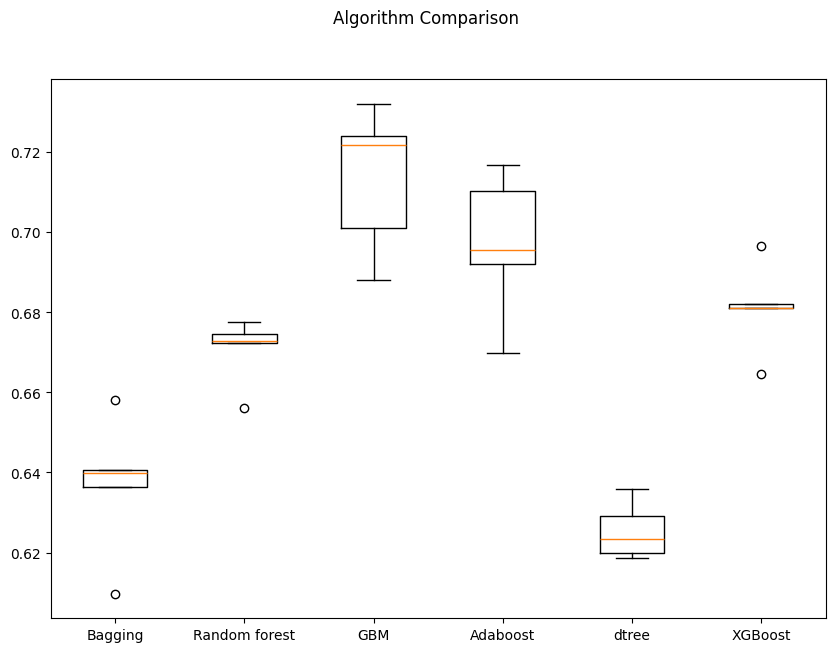

In [281]:
# Plotting boxplots for CV scores of all models defined above
fig = plt.figure(figsize=(10, 7))

fig.suptitle("Algorithm Comparison")
ax = fig.add_subplot(111)

plt.boxplot(results1)
ax.set_xticklabels(names)

plt.show()

- GBM has the best performance followed by AdaBoost model as per the validation performance on Undersampled dataset.



- After building 18 models, it was observed that both the GBM and Adaboost models, trained on an original dataset, as well as the GBM model & XGBoost trained on an oversampled dataset, exhibited strong performance on both the training and validation datasets.
- In comparision to oversampled and original dataset, all 6 models performs the worse with undersampled dataset, so we'll ignore tuning on undersampled dataset.
- Sometimes models might overfit after undersampling and oversampling, so it's better to tune the models to get a generalized performance
- We will tune these 5 models using the same data (orignal and oversampled) as we trained them on before

## Hyperparameter Tuning

### Tuning AdaBoostClassifier model with Original data

In [282]:
%%time

# defining model
Model = AdaBoostClassifier(random_state=1)

# Parameter grid to pass in RandomSearchCV
param_grid = {
    "n_estimators": [50, 100, 150, 200],
    "learning_rate": [0.01, 0.1, 0.5, 1.0],
    "estimator": [
        DecisionTreeClassifier(max_depth=1, random_state=1),
        DecisionTreeClassifier(max_depth=2, random_state=1),
        DecisionTreeClassifier(max_depth=3, random_state=1),
    ]
}

# Calling RandomizedSearchCV
randomized_cv = RandomizedSearchCV(
    estimator=Model,
    param_distributions=param_grid,
    n_iter=50,
    n_jobs=-1,
    scoring=scorer,
    cv=5,
    random_state=1
)

# Fitting parameters in RandomizedSearchCV
randomized_cv.fit(X_train, y_train)

print("Best parameters are {} with CV score={}:" .format(randomized_cv.best_params_, randomized_cv.best_score_))

Best parameters are {'n_estimators': 100, 'learning_rate': 0.1, 'estimator': DecisionTreeClassifier(max_depth=3, random_state=1)} with CV score=0.8232875111516604:
CPU times: user 10.1 s, sys: 1.22 s, total: 11.3 s
Wall time: 8min 52s


In [343]:
tuned_adb = AdaBoostClassifier(
    n_estimators=100,
    learning_rate=0.1,
    estimator=DecisionTreeClassifier(max_depth=3, random_state=1),
)
tuned_adb.fit(X_train, y_train)

AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3,
                                                    random_state=1),
                   learning_rate=0.1, n_estimators=100)

In [344]:
# Checking model's performance on training set
adb_train = model_performance_classification_sklearn(tuned_adb, X_train, y_train)
adb_train

,Accuracy,Recall,Precision,F1
0,0.751,0.876,0.779,0.824


In [345]:
# Checking model's performance on validation set
adb_val = model_performance_classification_sklearn(tuned_adb, X_val, y_val)
adb_val

,Accuracy,Recall,Precision,F1
0,0.751,0.870,0.782,0.823


### Tuning AdaBoostClassifier model with Oversampled data

In [286]:
%%time

# defining model
Model = AdaBoostClassifier(random_state=1)

# Parameter grid to pass in RandomSearchCV
param_grid = {
    "n_estimators": [50, 100, 150, 200],
    "learning_rate": [0.01, 0.1, 0.5, 1.0],
    "estimator": [
        DecisionTreeClassifier(max_depth=1, random_state=1),
        DecisionTreeClassifier(max_depth=2, random_state=1),
        DecisionTreeClassifier(max_depth=3, random_state=1),
    ]
}

# Calling RandomizedSearchCV
randomized_cv = RandomizedSearchCV(
    estimator=Model,
    param_distributions=param_grid,
    n_iter=50,
    n_jobs=-1,
    scoring=scorer,
    cv=5,
    random_state=1
)

# Fitting parameters in RandomizedSearchCV
randomized_cv.fit(X_train_over, y_train_over)

print("Best parameters are {} with CV score={}:" .format(randomized_cv.best_params_, randomized_cv.best_score_))

Best parameters are {'n_estimators': 150, 'learning_rate': 0.5, 'estimator': DecisionTreeClassifier(max_depth=3, random_state=1)} with CV score=0.8102671088493805:
CPU times: user 13.9 s, sys: 1.47 s, total: 15.4 s
Wall time: 11min 24s


In [287]:
tuned_adb_over = AdaBoostClassifier(
    n_estimators=150,
    learning_rate=0.5,
    estimator=DecisionTreeClassifier(max_depth=3, random_state=1),
)
tuned_adb_over.fit(X_train_over, y_train_over)

AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3,
                                                    random_state=1),
                   learning_rate=0.5, n_estimators=150)

In [288]:
# Checking model's performance on training set
adb_train_over = model_performance_classification_sklearn(tuned_adb_over, X_train_over, y_train_over)
adb_train_over

,Accuracy,Recall,Precision,F1
0,0.811,0.846,0.790,0.817


In [289]:
# Checking model's performance on validation set
adb_val_over = model_performance_classification_sklearn(tuned_adb_over, X_val, y_val)
adb_val_over

,Accuracy,Recall,Precision,F1
0,0.748,0.839,0.795,0.816


### Tuning Gradient Boosting model with Original data

In [290]:
%%time

#defining model
Model = GradientBoostingClassifier(random_state=1)

#Parameter grid to pass in RandomSearchCV
param_grid = {
    "init": [AdaBoostClassifier(random_state=1),DecisionTreeClassifier(random_state=1)],
    "n_estimators": np.arange(75,150,25),
    "learning_rate": [0.1, 0.01, 0.2, 0.05, 1],
    "subsample":[0.5,0.7,1],
    "max_features":[0.5,0.7,1],
}

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.recall_score)

#Calling RandomizedSearchCV
randomized_cv = RandomizedSearchCV(estimator=Model, param_distributions=param_grid, n_iter=50, scoring=scorer, cv=5, random_state=1, n_jobs = -1)

#Fitting parameters in RandomizedSearchCV
randomized_cv.fit(X_train, y_train)

print("Best parameters are {} with CV score={}:" .format(randomized_cv.best_params_,randomized_cv.best_score_))

Best parameters are {'subsample': 0.5, 'n_estimators': np.int64(125), 'max_features': 1, 'learning_rate': 0.01, 'init': AdaBoostClassifier(random_state=1)} with CV score=0.9398628795298727:
CPU times: user 6.6 s, sys: 885 ms, total: 7.49 s
Wall time: 5min 54s


In [291]:
tuned_gbm = GradientBoostingClassifier(
    subsample=0.5,
    n_estimators=125,
    max_features=1,
    learning_rate=0.01,
    init=AdaBoostClassifier(random_state=1),
)
tuned_gbm.fit(X_train, y_train)

GradientBoostingClassifier(init=AdaBoostClassifier(random_state=1),
                           learning_rate=0.01, max_features=1, n_estimators=125,
                           subsample=0.5)

In [292]:
# Checking model's performance on training set
gbm_train = model_performance_classification_sklearn(tuned_gbm, X_train, y_train)
gbm_train

,Accuracy,Recall,Precision,F1
0,0.722,0.940,0.725,0.819


In [293]:
# Checking model's performance on validation set
gbm_val = model_performance_classification_sklearn(tuned_gbm, X_val, y_val)
gbm_val

,Accuracy,Recall,Precision,F1
0,0.722,0.934,0.728,0.818


### Tuning Gradient Boosting model with Oversampled data

In [409]:
%%time

#defining model
Model = GradientBoostingClassifier(random_state=1)

#Parameter grid to pass in RandomSearchCV
param_grid = {
    "init": [AdaBoostClassifier(random_state=1),DecisionTreeClassifier(random_state=1)],
    "n_estimators": np.arange(75,150,25),
    "learning_rate": [0.1, 0.01, 0.2, 0.05, 1],
    "subsample":[0.5,0.7,1],
    "max_features":[0.5,0.7,1],
}

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.recall_score)

#Calling RandomizedSearchCV
randomized_cv = RandomizedSearchCV(estimator=Model, param_distributions=param_grid, n_iter=50, scoring=scorer, cv=5, random_state=1, n_jobs = -1)

#Fitting parameters in RandomizedSearchCV
randomized_cv.fit(X_train_over, y_train_over)

print("Best parameters are {} with CV score={}:" .format(randomized_cv.best_params_,randomized_cv.best_score_))

Best parameters are {'subsample': 0.7, 'n_estimators': np.int64(125), 'max_features': 0.7, 'learning_rate': 0.2, 'init': AdaBoostClassifier(random_state=1)} with CV score=0.8454456415279138:
CPU times: user 8.27 s, sys: 1.1 s, total: 9.37 s
Wall time: 6min 20s


In [410]:
tuned_gbm_over = GradientBoostingClassifier(
    subsample=0.7,
    n_estimators=125,
    max_features=0.7,
    learning_rate=0.2,
    init=AdaBoostClassifier(random_state=1),
)
tuned_gbm_over.fit(X_train_over, y_train_over)

GradientBoostingClassifier(init=AdaBoostClassifier(random_state=1),
                           learning_rate=0.2, max_features=0.7,
                           n_estimators=125, subsample=0.7)

In [411]:
# Checking model's performance on training set
gbm_train_over = model_performance_classification_sklearn(tuned_gbm_over, X_train_over, y_train_over)
gbm_train_over

,Accuracy,Recall,Precision,F1
0,0.819,0.860,0.794,0.826


In [412]:
# Checking model's performance on validation set
gbm_val_over = model_performance_classification_sklearn(tuned_gbm_over, X_val, y_val)
gbm_val_over

,Accuracy,Recall,Precision,F1
0,0.747,0.845,0.791,0.817


### Tuning XGB model with Oversampled data

In [298]:
%%time

# defining model
Model = XGBClassifier(random_state=1,eval_metric='logloss')

## Complete the code to define the hyperparameters
param_grid = {
    'n_estimators': [50, 100, 200, 300],
    'scale_pos_weight': [0.5, 1, 2],
    'learning_rate': [0.01, 0.1, 0.3],
    'gamma': [0, 0.1, 1],
    'subsample': [0.6, 0.8, 1.0]
}

## Complete the code to set the cv parameter
randomized_cv = RandomizedSearchCV(estimator=Model, param_distributions=param_grid, n_iter=50, n_jobs = -1, scoring=scorer, cv=5, random_state=1)

#Fitting parameters in RandomizedSearchCV
randomized_cv.fit(X_train_over,y_train_over)## Complete the code to fit the model on over sampled data

print("Best parameters are {} with CV score={}:" .format(randomized_cv.best_params_,randomized_cv.best_score_))

Best parameters are {'subsample': 0.6, 'scale_pos_weight': 2, 'n_estimators': 50, 'learning_rate': 0.01, 'gamma': 0} with CV score=0.9997061704211557:
CPU times: user 5.73 s, sys: 697 ms, total: 6.43 s
Wall time: 2min 29s


In [299]:
## Complete the code to define the best model
xgb2 = XGBClassifier(
    random_state=1,
    subsample=0.8,
    scale_pos_weight=2,
    n_estimators=200,
    learning_rate=0.1,
    gamma=1,
)

xgb2.fit(X_train_over, y_train_over)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=1, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, random_state=1, ...)

In [300]:
xgb2_train_perf = model_performance_classification_sklearn(
    xgb2, X_train_over, y_train_over
)
xgb2_train_perf

,Accuracy,Recall,Precision,F1
0,0.850,0.980,0.777,0.867


In [301]:
## Complete the code to print the model performance on the validation data.
xgb2_val_perf = model_performance_classification_sklearn(xgb2, X_val, y_val)
xgb2_val_perf

,Accuracy,Recall,Precision,F1
0,0.730,0.925,0.738,0.821


- XGBoost is overfitting as its performace dropped significantly from training to validation set. So, we cannot rely on this model.

## Model Comparison and Final Model Selection

In [413]:
## training performance comparison

models_train_comp_df = pd.concat(
    [
        gbm_train_over.T,
        xgb2_train_perf.T,
        adb_train_over.T,
        gbm_train.T,
        adb_train.T

    ],
    axis=1,
)
models_train_comp_df.columns = [
    "Gradient Boosting tuned with oversampled data",
    "XGBoost tuned with oversampled data",
    "AdaBoost tuned with oversampled data",
    "Gradient Boosting tuned with original data",
    "AdaBoost tuned with original data",

]
print("Training performance comparison:")
models_train_comp_df

Training performance comparison:


,Gradient Boosting tuned with oversampled data,XGBoost tuned with oversampled data,AdaBoost tuned with oversampled data,Gradient Boosting tuned with original data,AdaBoost tuned with original data
Accuracy,0.819,0.850,0.811,0.722,0.751
Recall,0.860,0.980,0.846,0.940,0.876
Precision,0.794,0.777,0.790,0.725,0.779
F1,0.826,0.867,0.817,0.819,0.824


In [414]:
# validation performance comparison

models_val_comp_df = pd.concat(
    [
        gbm_val_over.T,
        xgb2_val_perf.T,
        adb_val_over.T,
        gbm_val.T,
        adb_val.T
    ],
    axis=1,
)
models_val_comp_df.columns = [
    "Gradient Boosting tuned with oversampled data",
    "XGBoost tuned with oversampled data",
    "AdaBoost tuned with oversampled data",
    "Gradient Boosting tuned with original data",
    "AdaBoost tuned with original data",

]
print("Validation performance comparison:")
models_val_comp_df

Validation performance comparison:


,Gradient Boosting tuned with oversampled data,XGBoost tuned with oversampled data,AdaBoost tuned with oversampled data,Gradient Boosting tuned with original data,AdaBoost tuned with original data
Accuracy,0.747,0.730,0.748,0.722,0.751
Recall,0.845,0.925,0.839,0.934,0.870
Precision,0.791,0.738,0.795,0.728,0.782
F1,0.817,0.821,0.816,0.818,0.823


- XGBoost certainly has the best recall (almost 1.0) trained over oversampled data but Precision and Accuracy falls miserably low, similar performance for AdaBoost trained over original dataset. So, we can rule those out.
- Gradient Boosting with original data has good recall but generally low in precision and accuracy with F1 score better (0.003) than GBM and AdaBoost on oversampled dataset which is not significant enough to consider.

- GBM and Adaboost with oversampled data goes hand in hand, they both have similar Accuracy, Precision and Recall scores on validation data so we can consider them both generalized and make decision after test performace.

In [415]:
# Let's check the performance on test set
test_adb = model_performance_classification_sklearn(tuned_adb_over, X_test, y_test)
print("AdaBoost on oversampled data\n", test_adb)

test_gbm = model_performance_classification_sklearn(tuned_gbm_over, X_test, y_test)
print("GBM on oversampled data\n", test_gbm)

AdaBoost on oversampled data
    Accuracy  Recall  Precision    F1
0     0.735   0.838      0.781 0.808
GBM on oversampled data
    Accuracy  Recall  Precision    F1
0     0.736   0.846      0.778 0.811


- The Gradient Boosting Model trained on oversampled data has given ~85% recall & F1 score on the test set, slightly better than Ada Boost Model while Accuracy and Precision nearly same.
- So, GBM is a generalized model.

### Feature Importance

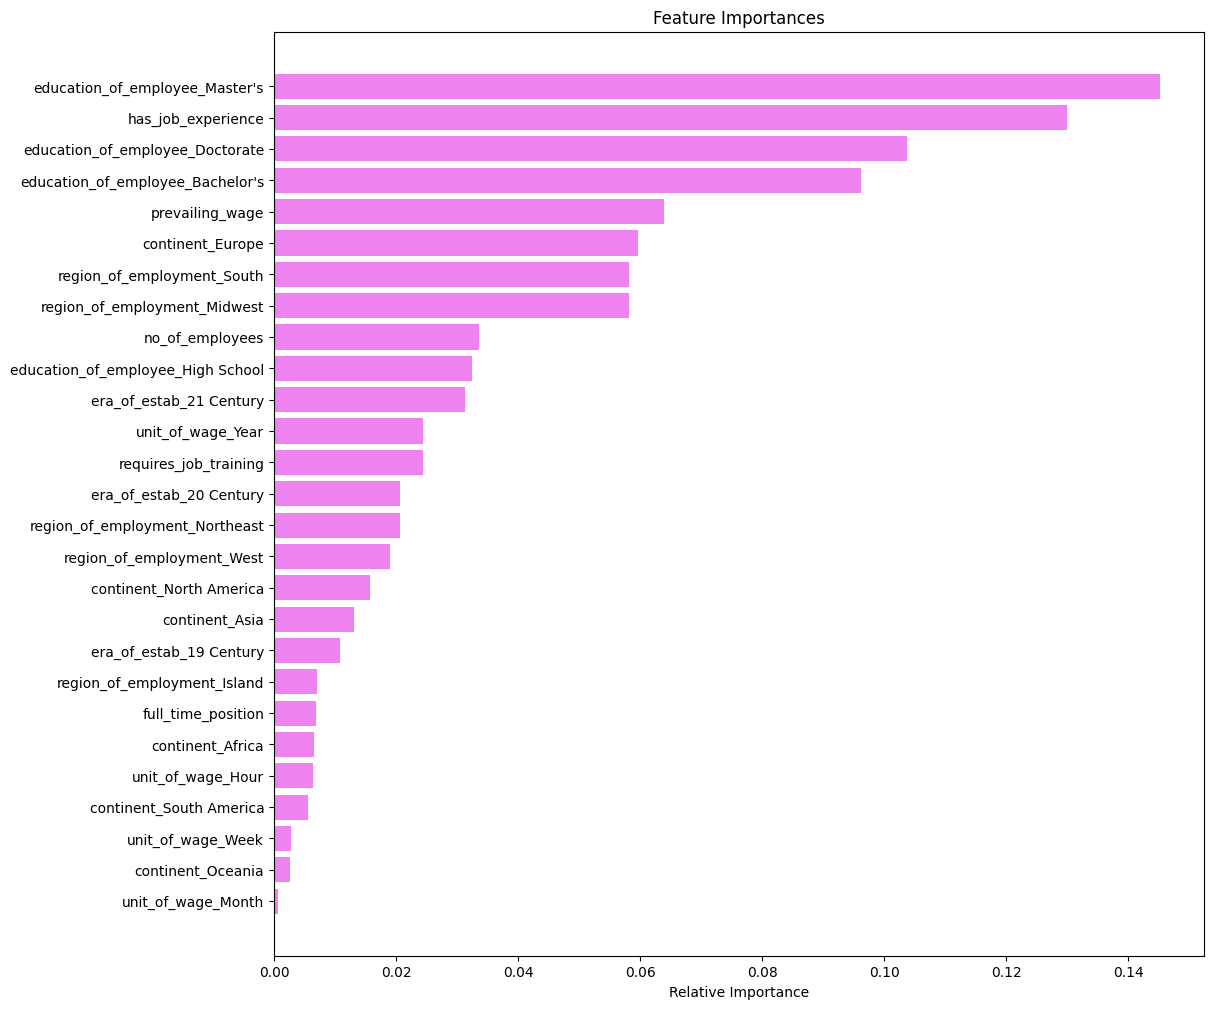

In [416]:
# Print the feature importances from the best model
feature_names = X_train.columns
importances = tuned_gbm_over.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(12, 12))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color="violet", align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

- We can see that education_of_employee_Master's, has_job_experience, education_of_employee_Bachelor's & education_of_employee_Doctorate are the most important features for making predictions
- These results aligns perfectly well with the correlation between important features and case_status as seen early in BiVariate/Multi-variate analysis for eg: target has the highest correlation with employee's have Master's degree (+0.20) as their education, and then if they have job experience whereas it is negatively correlated with the monthly unit of wage.
- Even counter plots gave some evidence how these features are most important to consider with respect to the case_status.

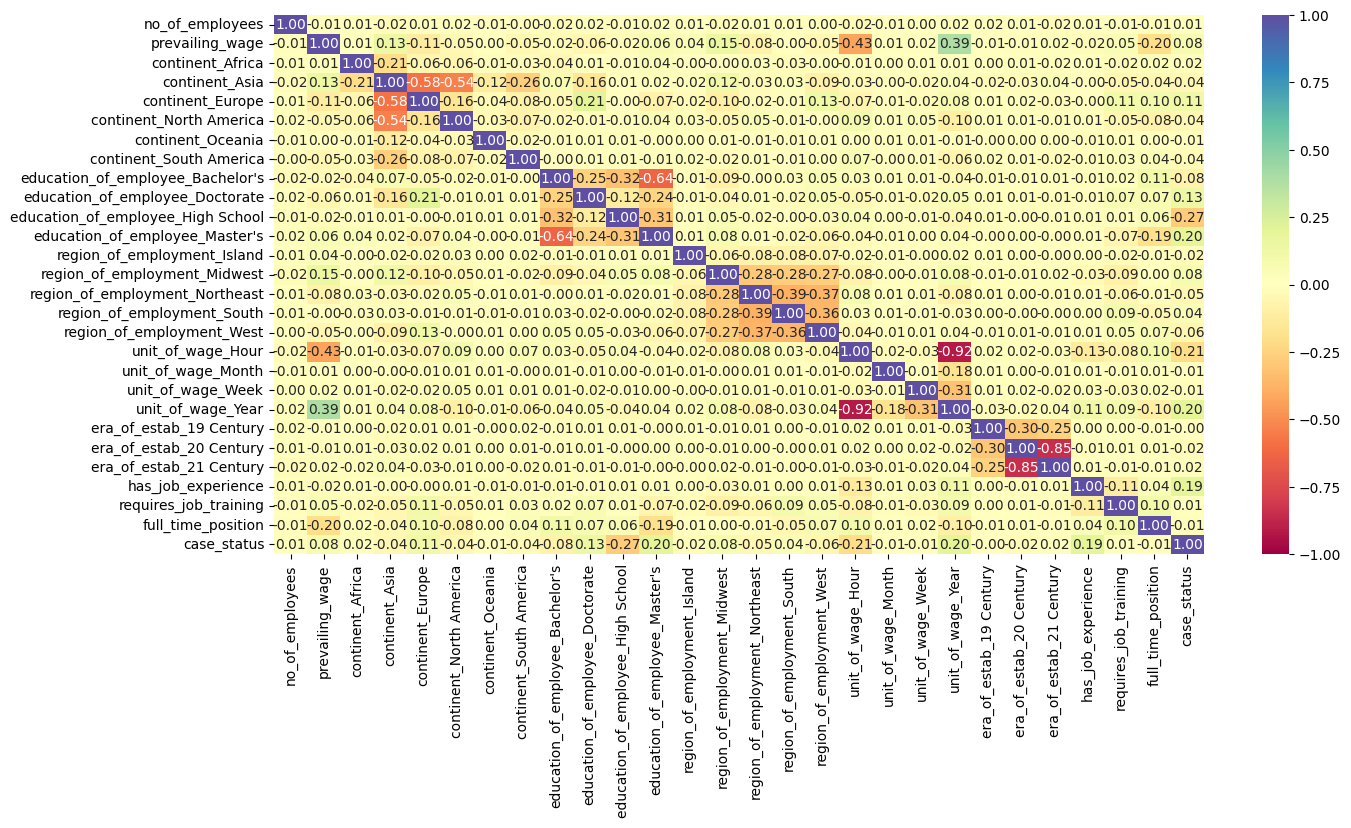

In [306]:
# Verify feature importance correlation with the target
plt.figure(figsize=(15, 7))
data9 = pd.concat([X, y], axis=1)
sns.heatmap(data9.corr(numeric_only = True), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral")
plt.show()

In [307]:
# Get the F1 score for Denied case status
y_pred_test = tuned_gbm_over.predict(X_test)
print("Test F1-score (Denied):", f1_score(y_test, y_pred_test, pos_label=0))

Test F1-score (Denied): 0.5624796084828712


- It's more than 55% which can mean some false positives but more trustworthy than other models without significantly major impact on decision making.

# Business Insights and Recommendations

* An employee with higher education and job experience has more chances of getting his/her visa approved.
* These factors have strong impact on case status, employees with Master's degree have will have more Certified case status than just High school degree. Likewise having a job experience plays a vital thing in case status decision.
* Monthly wage is certainly not recommended because it's highly likely that the worker is temporary and case should not be acceped for approval.
* Company can take favorable actions to maintain prevailing wage in correlation with yearly unit of wage.
* Employees from Europe have higher chances of getting visa approved, considering low regional costs in the area. Also, there's more employees with Doctorate degree from Europe.
* Size of the company is also important factor, this indicates that higher wages and larger company sizes are the most significant predictors of visa certification, reflecting the importance of competitive compensation and organizational capacity in meeting visa requirements.
* If the company is located in South or Midwest, employees are most likely eligible for visal approval because it indicates higher regional labour demand.
* It would be wise to approve visa's with Master's degree or higher education first and make sure the Bachelor's degree is must. Education is very important factor in general to know the eligibility of individual to contribute in respected company.
* If they have only High School level education then denial is recommended in that case.
* I'd recommend against approving visas for hourly or monthly paid employees, it indicates they are temporary contractors and might not stick around with company for long time.
* Focus on employees from the most recent companies, it matters a lot the company is establised in 21st century. Approving visas for newer company employees gives some confidence that the company will last longer and has good decision making in highering employees with fresh talent.
* Targetting bigger companies is always a good filter, since we know there'll be more systematic process to hire and even keep talented employees, so approving visas for candidates of companies with more number of employees is recommended.
* In general there's a lot of negative correlation among predictors but carefully targtting appropriate region and talent as mentioned above will help soothen the selection process.

# <a name='link1'>Appendix: Detailed Exploratory Data Analysis (EDA)</a>

## Univariate analysis

In [308]:
# function to plot a boxplot and a histogram along the same scale.

def histogram_boxplot(data, feature, figsize=(12, 7), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (12,7))
    kde: whether to the show density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a star will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins, palette="winter"
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

### Observations on yr_of_establishment

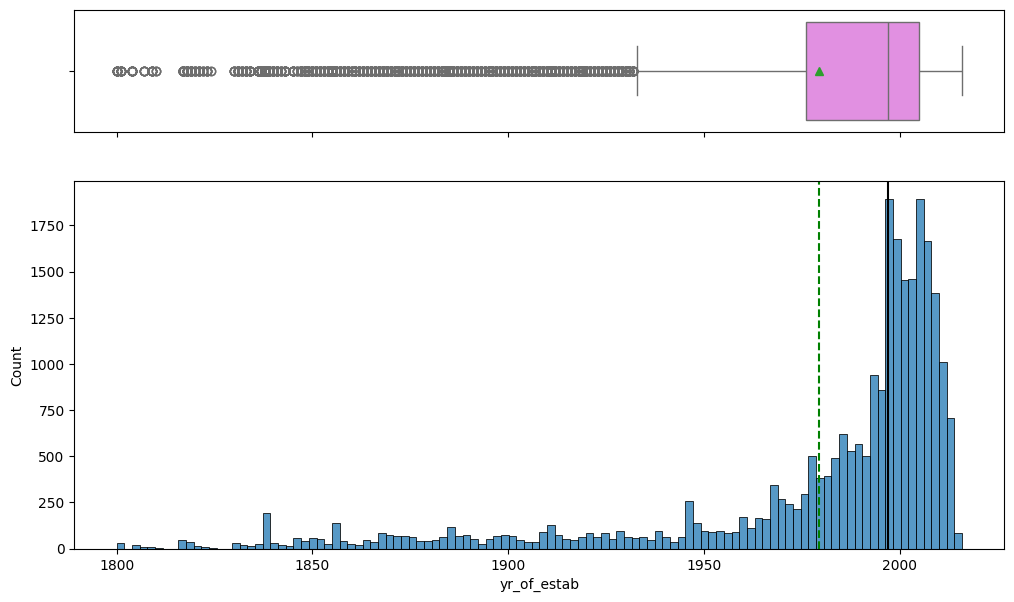

In [309]:
histogram_boxplot(data, "yr_of_estab");

* Distribution of yrs of establishment is heavily right-skewed, with most values clustering between 1975-2000.
* There are many outliers on the left (earlier years), extending back to 1800.
* Most companies were established relatively recently, with a few much older ones.
* We can bucket this into centuries later.

### Observations on prevailing_wage

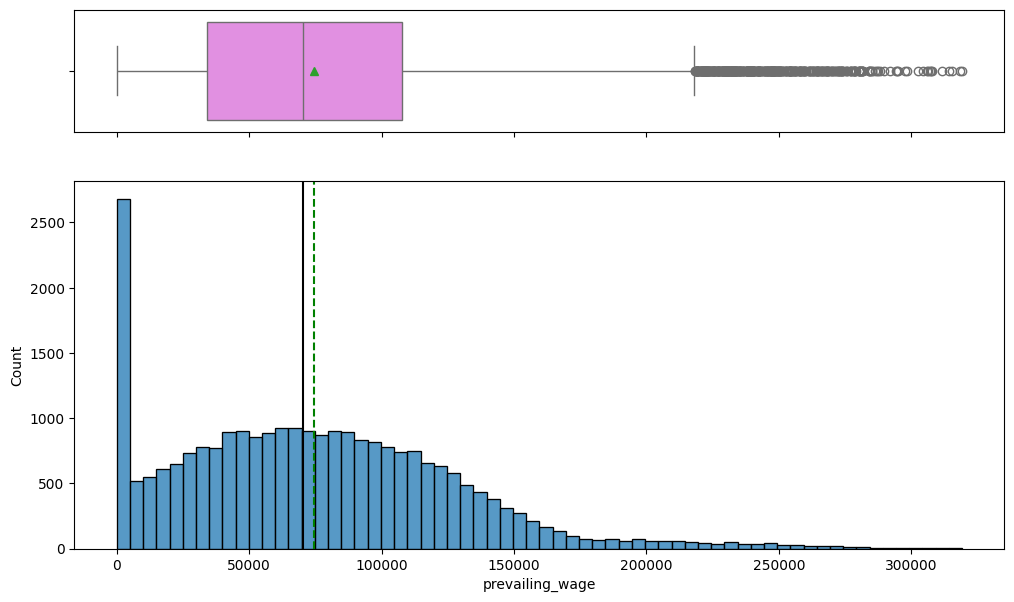

In [310]:
histogram_boxplot(data, "prevailing_wage")

* The x-axis represents prevailing wages (0 to 300,000), and the y-axis shows the count (0 to 2500). The distribution is right-skewed, with a peak around 0 where the count exceeds 2500. Most wages are below 100,000, with a long tail extending to above 300,000, indicating a few high outliers. A green dashed line at around 75,000 marks a point of interest, possibly the median.
* The box spans roughly 25,000 to 125,000, showing the interquartile range (IQR). Whiskers extend to more than 300,000, with a green triangle marking an outlier near 75,000.
* The majority of prevailing wages are between 25,000 and 150,000, with a right-skewed distribution indicating a small number of significantly higher wages.

In [311]:
# function to create labeled barplots


def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with percentage at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    """

    total = len(data[feature])  # length of the column
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 1, 5))
    else:
        plt.figure(figsize=(n + 1, 5))

    plt.xticks(rotation=90, fontsize=15)
    ax = sns.countplot(
        data=data,
        x=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n].sort_values(),
    )

    for p in ax.patches:
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # percentage of each class of the category
        else:
            label = p.get_height()  # count of each level of the category

        x = p.get_x() + p.get_width() / 2  # width of the plot
        y = p.get_height()  # height of the plot

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # annotate the percentage

    plt.show()  # show the plot

### Observations on continent

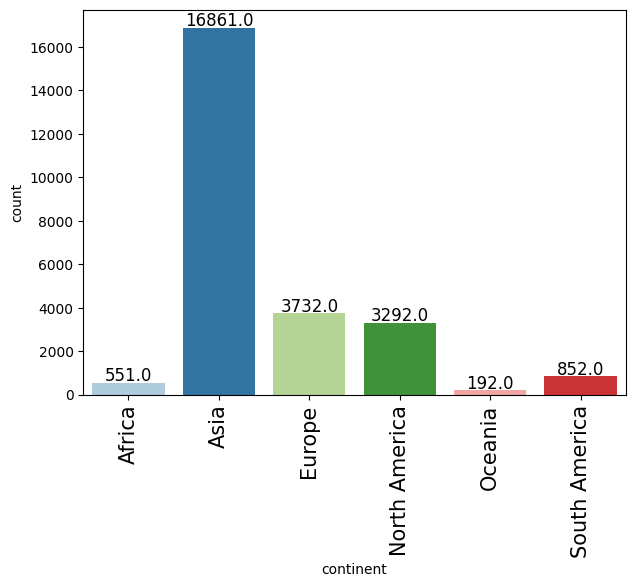

In [312]:
labeled_barplot(data, "continent")

In [313]:
data[data['continent'] == 'Asia']['continent'].count() * 100 / data['continent'].count() # Get percentage count for Asia

np.float64(66.1734693877551)

* Asia has the highest count at 16,861, about 66% of the applicants are from Asia, significantly outpacing others. Europe and North America follow with 3,732 and 3,292, respectively. South America and Oceania have much lower counts at 852 and 192. Africa has the lowest count at 551.
* This suggests a heavy concentration in Asia, with Europe and North America having moderate counts, while Africa, South America, and Oceania are notably lower

### Observations on education_employee

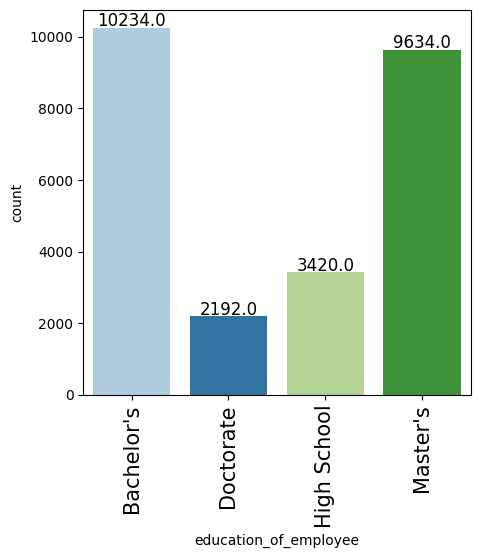

In [314]:
labeled_barplot(data, "education_of_employee")

In [315]:
data[data['education_of_employee'] == 'Bachelor\'s']['education_of_employee'].count() * 100 / data['education_of_employee'].count() # Get percentage count for Bachelor's degree

np.float64(40.16483516483517)

* 40% of the applicants are with Bachelor's degree. About 38% holds Master's degree.
* Workforce is composed of employees with higher education (Bachelor's and Master's), with fewer having only a high school education or a doctorate.

### Observations on has_job_experience

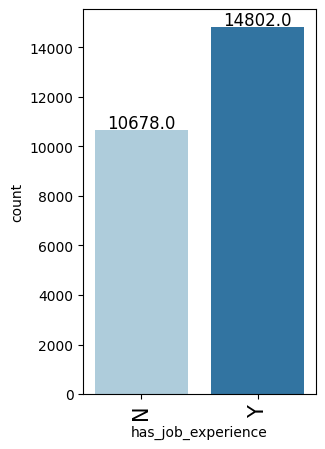

In [316]:
labeled_barplot(data, "has_job_experience")

In [317]:
df.shape

(25480, 11)

* 14802 employees have job experience which is 58% of the data while 42% doesn't
* We have more employees with job experience

### Observations on requires_job_training

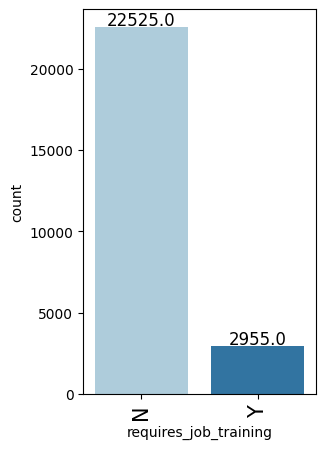

In [318]:
labeled_barplot(data, "requires_job_training")

* 88% of applicants does not require job training while very few does.
* This feature is aligned with job experience and education level.

### Observations on region_of_employment

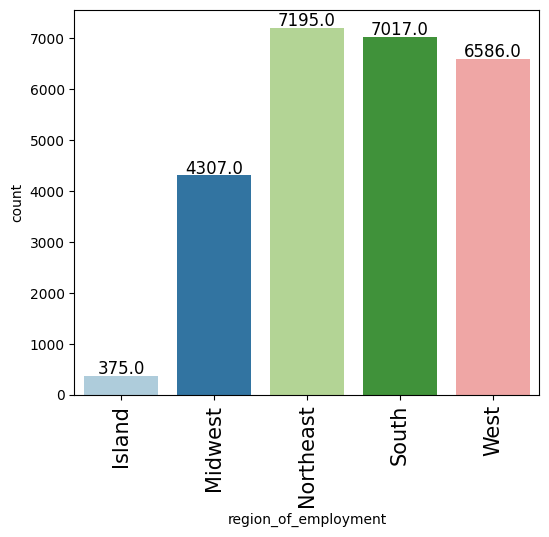

In [319]:
labeled_barplot(data, "region_of_employment")

* The Northeast has the highest number of cases - 28.24%, followed closely by the South - 27.54% and West - 25.85%.
* This suggests that visa applications are more concentrated in the Northeast, South, and West, with the Island region being significantly less common.

### Observations on unit_of_wage

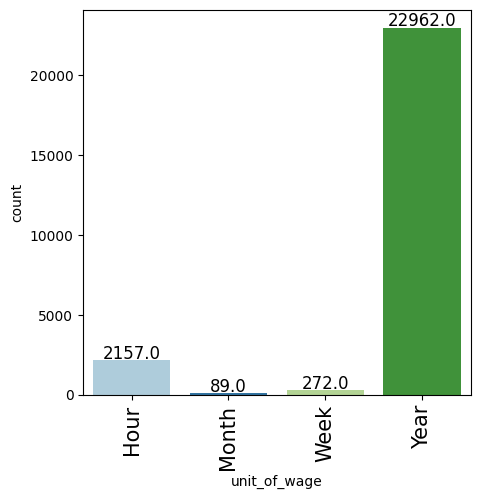

In [320]:
labeled_barplot(data, "unit_of_wage")

* The vast majority of cases (90.12%) have wages reported on a yearly basis, while monthly wages are the least common at 0.35%.

### Observations on full_time_position

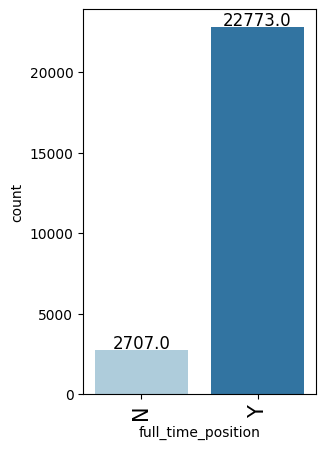

In [321]:
labeled_barplot(data, "full_time_position")

* The vast majority of positions (89.38%) are full-time, while 10.62% are not.

### Observations on target variable case_status

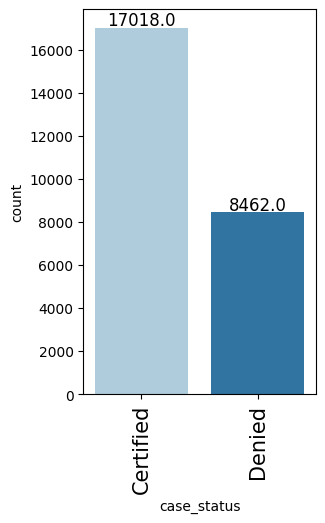

In [322]:
labeled_barplot(data, "case_status")

* This shows that about two-thirds of the visa applications (66.79%) were certified, while one-third (33.21%) were denied.
* There's still high chances of getting more visa approvals by picking the right features to focus on.

## Bivariate/ Multi-variate Analysis

In [323]:
# converting target variable into binary int value type
num_target = df["case_status"].apply(lambda x: 1 if x == "Certified" else 0)

In [324]:
# make another copy
data_copy = data.copy()

In [325]:
# Adding dependent variable to predictors
data_copy["case_status"] = num_target

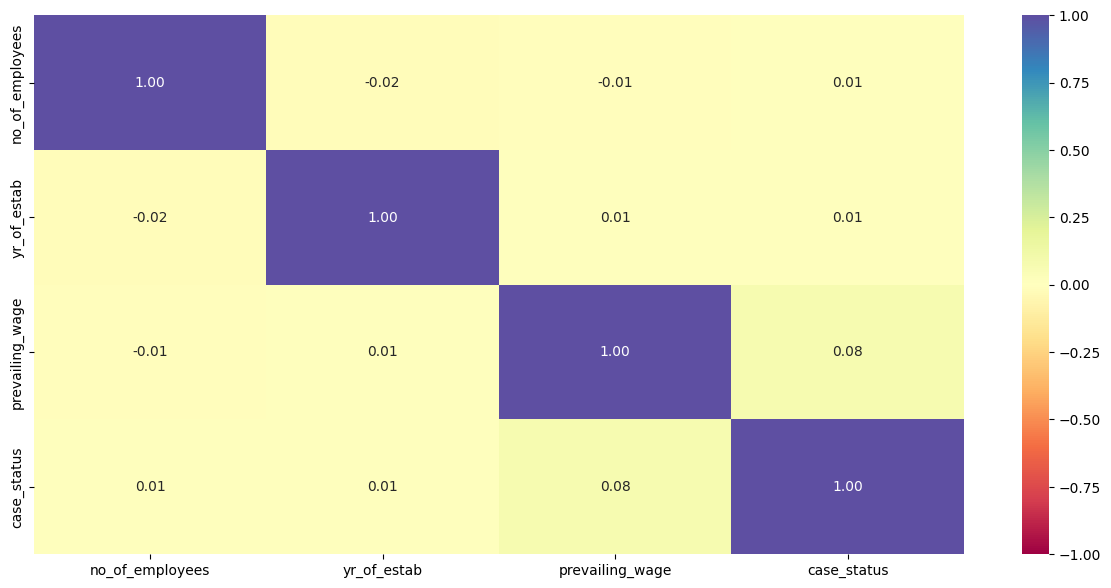

In [326]:
# Show correlation between all the numerical variables
plt.figure(figsize=(15, 7))
sns.heatmap(data_copy.corr(numeric_only = True), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral")
plt.show()

* The strongest (though still weak) correlation is between prevailing_wage and case_status at 0.08, suggesting that higher wages might slightly increase the chances of visa certification.
* All other correlations are negligible, indicating these variables are mostly independent in terms of linear relationships.
* In fact No. of Employees are negatively correlated with prevailing wages and years of establishments.

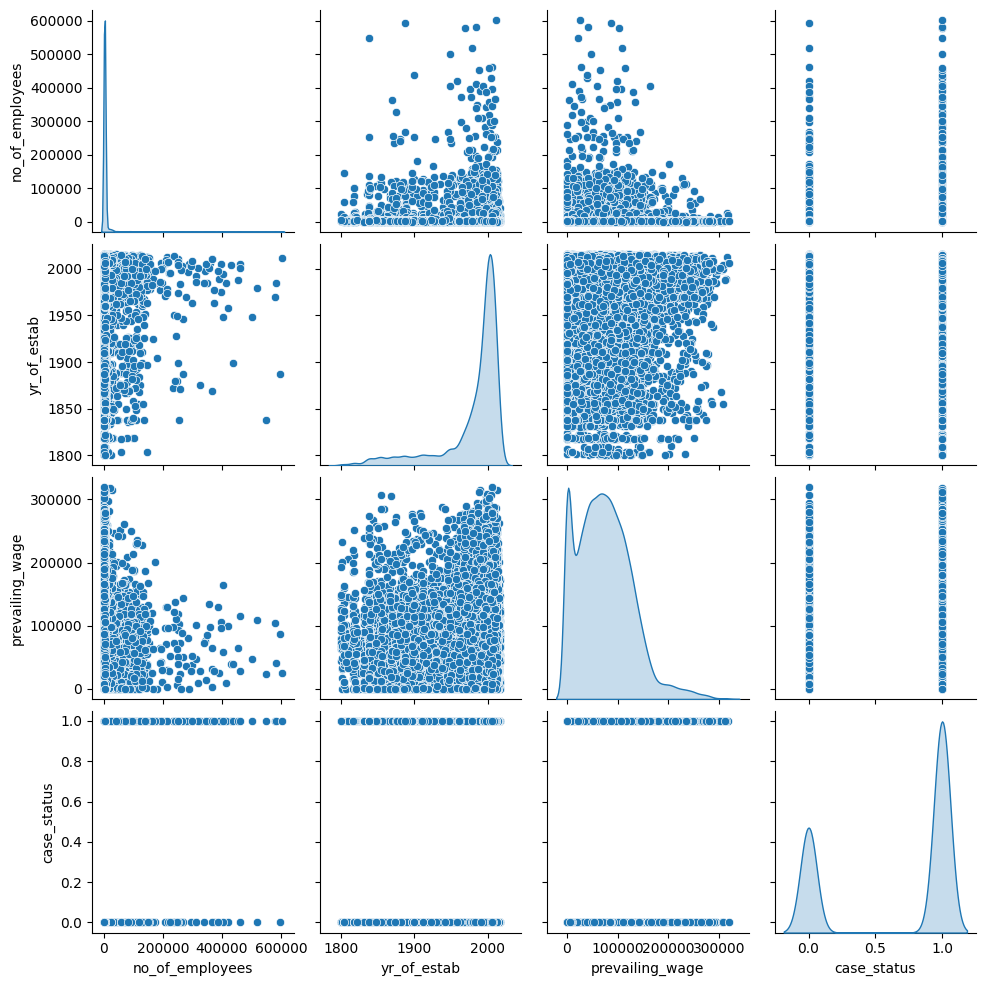

In [327]:
# Represent the same using pairplot
sns.pairplot(data=data_copy, diag_kind="kde")
plt.show()

* The scatter plots show no strong visual correlation between these variables, consistent with the earlier correlation heatmap (e.g., correlations like -0.02, 0.01, 0.08).
Outliers are present in no_of_employees and prevailing_wage, which may skew analyses but we are not addressing prevailing_wage for this dataset as we need it as is in correlation with the unit_of_wage.

In [328]:
# function to plot stacked bar chart

def stacked_barplot(data, predictor, target):
    """
    Print the category counts and plot a stacked bar chart

    data: dataframe
    predictor: independent variable
    target: target variable
    """
    count = data[predictor].nunique()
    sorter = data[target].value_counts().index[-1]
    tab1 = pd.crosstab(data[predictor], data[target], margins=True).sort_values(
        by=sorter, ascending=False
    )
    print(tab1)
    print("-" * 120)
    tab = pd.crosstab(data[predictor], data[target], normalize="index").sort_values(
        by=sorter, ascending=False
    )
    tab.plot(kind="bar", stacked=True, figsize=(count + 1, 5))
    plt.legend(
        loc="lower left", frameon=False,
    )
    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.show()

### Continent vs Case_Status

case_status    Certified  Denied    All
continent                              
All                17018    8462  25480
Asia               11012    5849  16861
North America       2037    1255   3292
Europe              2957     775   3732
South America        493     359    852
Africa               397     154    551
Oceania              122      70    192
------------------------------------------------------------------------------------------------------------------------


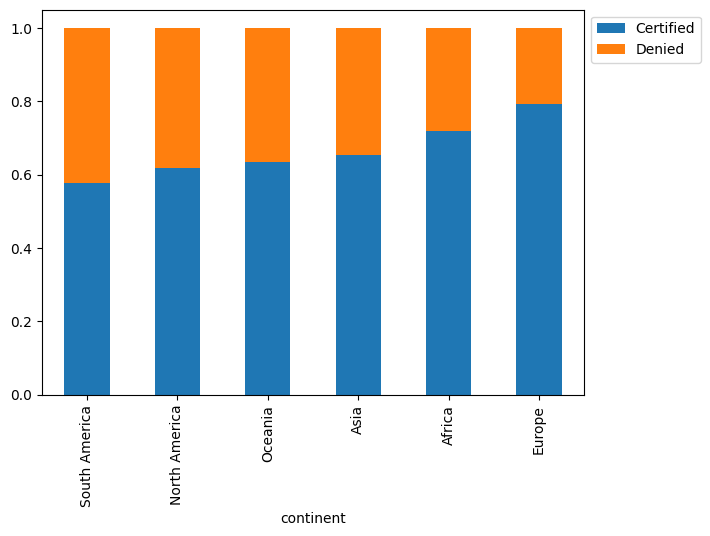

In [329]:
stacked_barplot(data, "continent", "case_status")

* Europe (80.77%) and Africa (80%) have the highest certification rates. North America (64.86%) and Asia (65.15%) have the lowest certification rates.
* The overall trend aligns with the earlier case_status distribution (66.79% Certified, 33.21% Denied), but there are variations by continent, with Europe and Africa showing higher success rates for visa certification.

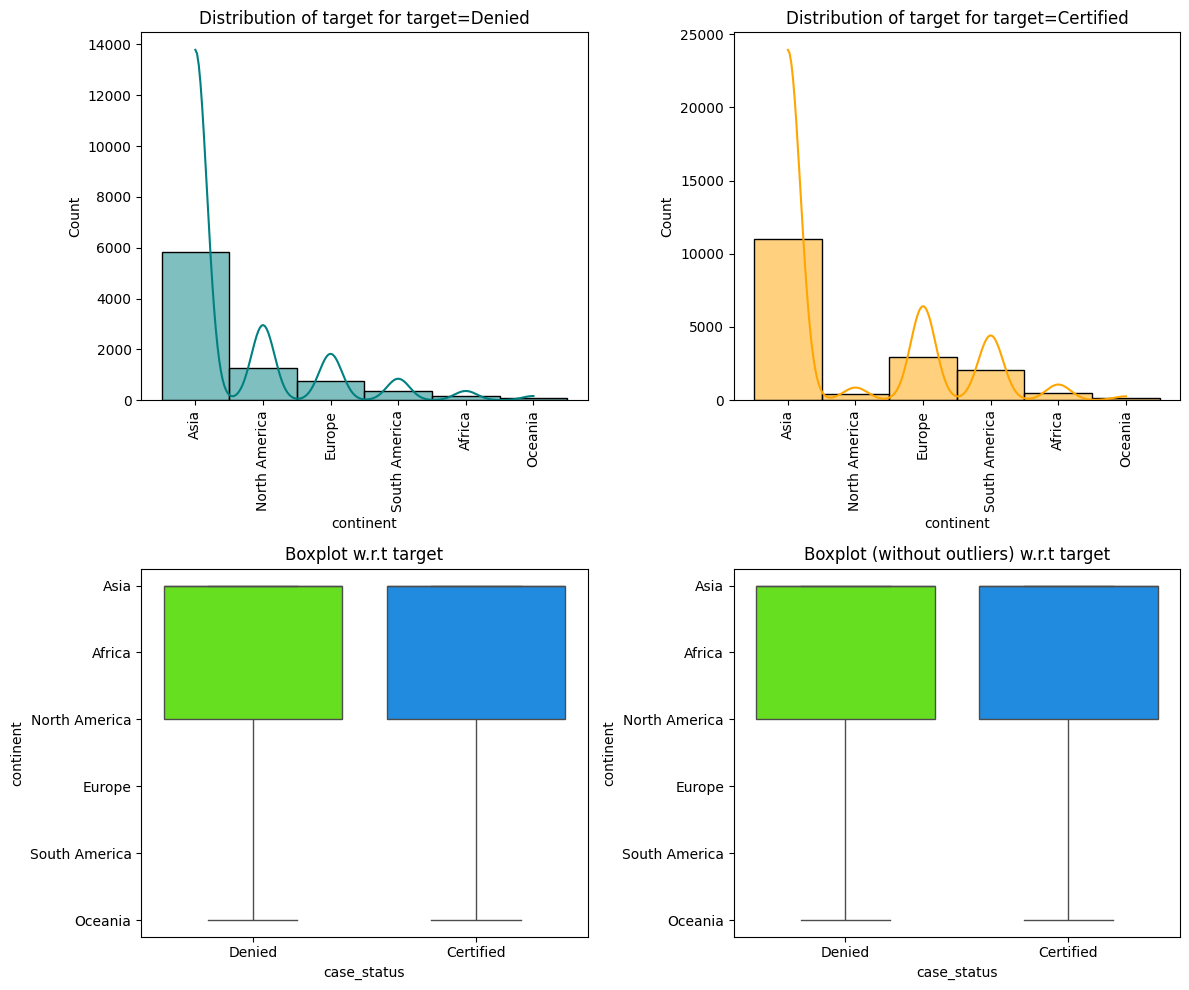

In [330]:
distribution_plot_wrt_target(data, "continent", "case_status")

* Asia has the largest number of cases (both Denied and Certified) and the most variability in target values, as seen in the histograms and boxplots.
* "Certified" cases tend to have a slightly higher median target value than "Denied" cases across most continents, though the difference is small.
* The presence of outliers, especially in Asia, suggests that while most target values are low, there are some extreme cases with very high values.
* Other continents like Africa, South America, and Oceania have fewer cases and less variability in target, indicating more consistency in the data for these regions.

### Education_Of_Employee vs Case_Status

case_status            Certified  Denied    All
education_of_employee                          
All                        17018    8462  25480
Bachelor's                  6367    3867  10234
High School                 1164    2256   3420
Master's                    7575    2059   9634
Doctorate                   1912     280   2192
------------------------------------------------------------------------------------------------------------------------


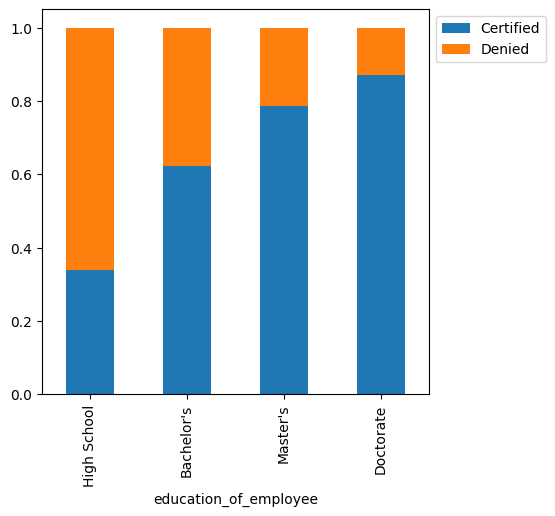

In [331]:
stacked_barplot(data, "education_of_employee", "case_status")

* Doctorate holders have the highest certification rate at 88.46%, followed by Master's (74.27%) and Bachelor's (67.34%).
* While just High School education has the lowest certification rate at 48.86%, with a slightly higher chance of denial (51.14%).
* There is a clear trend that higher education levels are associated with higher visa certification rates. This aligns with the intuition that advanced education might correlate with better job qualifications or skills, increasing the likelihood of visa approval.
* The overall certification rate (66.79% Certified, 33.21% Denied from earlier analysis) is reflected here, but education level significantly impacts the outcome, with Doctorate holders far exceeding the average certification rate.

### Has_Job_Experience vs Case_Status

case_status         Certified  Denied    All
has_job_experience                          
All                     17018    8462  25480
N                        5994    4684  10678
Y                       11024    3778  14802
------------------------------------------------------------------------------------------------------------------------


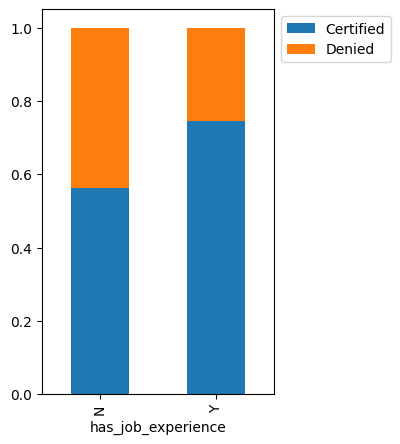

In [332]:
stacked_barplot(data, "has_job_experience", "case_status")

* Applicants with job experience have a significantly higher certification rate (74.68%) compared to those without (54.76%). This suggests that having job experience increases the likelihood of visa certification by about 20 percentage points.
* Job experience appears to be a positive factor in visa approval, likely because it indicates relevant skills or qualifications that make the applicant more appealing for certification

### Requires_Job_Training vs Case_Status

case_status            Certified  Denied    All
requires_job_training                          
All                        17018    8462  25480
N                          15012    7513  22525
Y                           2006     949   2955
------------------------------------------------------------------------------------------------------------------------


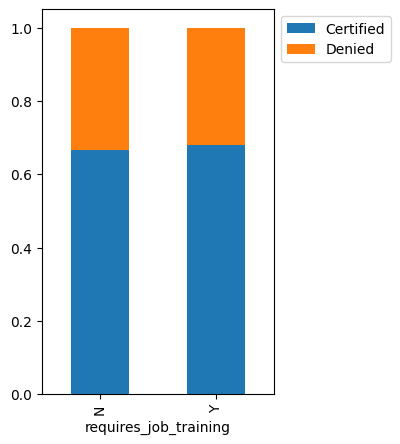

In [333]:
stacked_barplot(data, "requires_job_training", "case_status")

* Applicants who require job training (Y) have a slightly higher certification rate (69.84%) compared to those who do not (65.35%). The difference is about 4.5 percentage points, suggesting that requiring job training might slightly improve the chances of visa certification.
* Contrary to what might be expected, requiring job training does not negatively impact visa certification rates. It may indicate that employers are willing to invest in training, which could reflect confidence in the applicant’s potential, possibly influencing a positive outcome.

### No_Of_Employees vs Case_Status

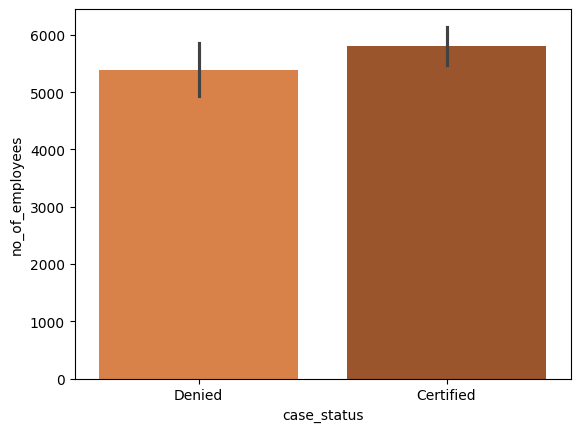

In [334]:
sns.barplot(y='no_of_employees', x='case_status', data=data, palette='Oranges_d');

* The number of employees does not appear to significantly influence the likelihood of certification or denial, as the distributions are nearly identical. About 75% of cases in both groups involve companies with fewer than 5,000 employees, and outliers above 100,000 employees are equally rare in both groups.

### Yr_Of_Estab vs Case_Status

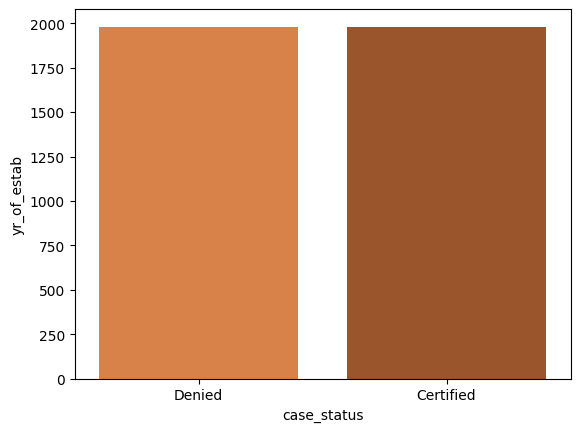

In [335]:
sns.barplot(y='yr_of_estab', x='case_status', data=data, palette='Oranges_d');

* Distributions are nearly identical, indicating yr_of_estab has little impact on case_status (consistent with their negligible correlation of 0.01).
* So we'll be converting into eras or centuries of establishment instead, to make it more significant to the target case_status.

### Region_Of_Employment vs Case_Status

case_status           Certified  Denied    All
region_of_employment                          
All                       17018    8462  25480
Northeast                  4526    2669   7195
West                       4100    2486   6586
South                      4913    2104   7017
Midwest                    3253    1054   4307
Island                      226     149    375
------------------------------------------------------------------------------------------------------------------------


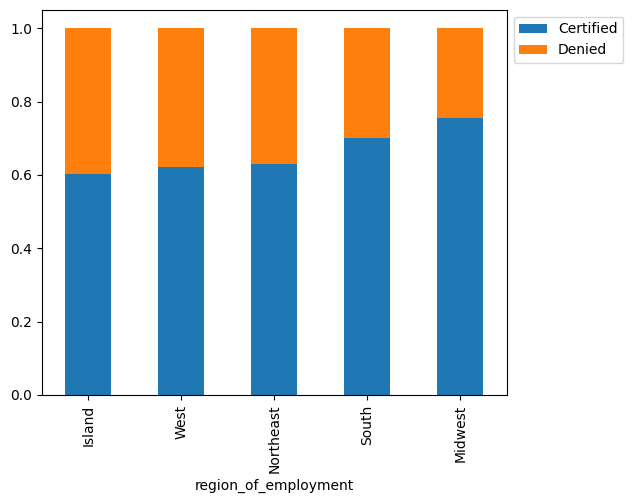

In [336]:
stacked_barplot(data, "region_of_employment", "case_status")

* Midwest has the highest certification rate (80%), while Island and West have the lowest (60%). This suggests regional differences in visa approval rates, with Midwest being the most favorable.

### Prevailing_Wage vs Case_Status

<Axes: xlabel='prevailing_wage', ylabel='case_status'>

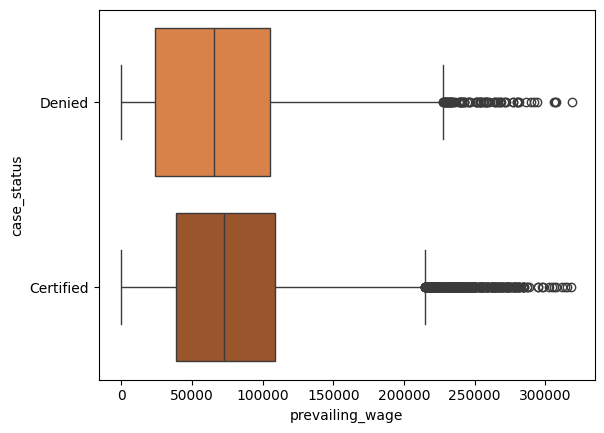

In [337]:
sns.boxplot(x='prevailing_wage', y='case_status', data=data, palette='Oranges_d')

* Both distributions exhibit positive skewness (right-skewed), as the upper tails (higher wages) are longer and contain more outliers.
* The "Denied" cases show stronger positive skewness due to a longer upper whisker and more high-wage outliers compared to the "Certified" cases.
* Both are positively skewed, with the "Denied" cases displaying a more noticeable right skew due to greater asymmetry and more extreme high-wage outliers.

### Unit_Of_Wage vs Case_Status

case_status   Certified  Denied    All
unit_of_wage                          
All               17018    8462  25480
Year              16047    6915  22962
Hour                747    1410   2157
Week                169     103    272
Month                55      34     89
------------------------------------------------------------------------------------------------------------------------


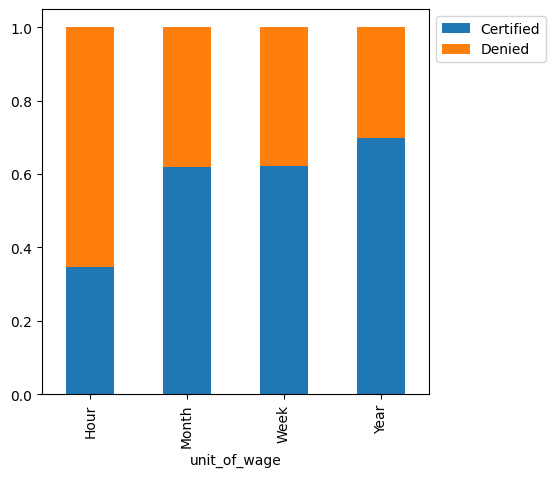

In [338]:
stacked_barplot(data, "unit_of_wage", "case_status")

* Yearly wage units have the highest certification rate (70%), while hourly wages have the lowest (50%). This suggests that higher, more stable wage units (like yearly) may improve certification chances.

### Full_Time_Postition vs Case_Status

case_status         Certified  Denied    All
full_time_position                          
All                     17018    8462  25480
Y                       15163    7610  22773
N                        1855     852   2707
------------------------------------------------------------------------------------------------------------------------


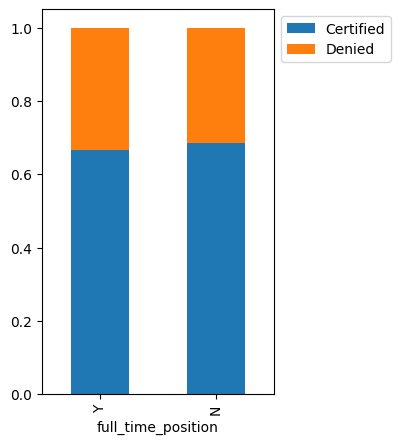

In [339]:
stacked_barplot(data, "full_time_position", "case_status")

* Certification rates are nearly identical for full-time (65%) and non-full-time positions (67%), suggesting full_time_position has little impact on case_status. This aligns with the overall certification rate (66.79%).



In [340]:
### Function to plot distributions


def distribution_plot_wrt_target(data, predictor, target):

    fig, axs = plt.subplots(2, 2, figsize=(12, 10))

    target_uniq = data[target].unique()

    axs[0, 0].set_title("Distribution of target for target=" + str(target_uniq[0]))
    sns.histplot(
        data=data[data[target] == target_uniq[0]],
        x=predictor,
        kde=True,
        ax=axs[0, 0],
        color="teal",
    )

    axs[0, 1].set_title("Distribution of target for target=" + str(target_uniq[1]))
    sns.histplot(
        data=data[data[target] == target_uniq[1]],
        x=predictor,
        kde=True,
        ax=axs[0, 1],
        color="orange",
    )

    axs[1, 0].set_title("Boxplot w.r.t target")
    sns.boxplot(data=data, x=target, y=predictor, ax=axs[1, 0], palette="gist_rainbow")

    axs[1, 1].set_title("Boxplot (without outliers) w.r.t target")
    sns.boxplot(
        data=data,
        x=target,
        y=predictor,
        ax=axs[1, 1],
        showfliers=False,
        palette="gist_rainbow",
    )

    plt.tight_layout()
    plt.show()

### Education_Of_Employee vs Case_Status

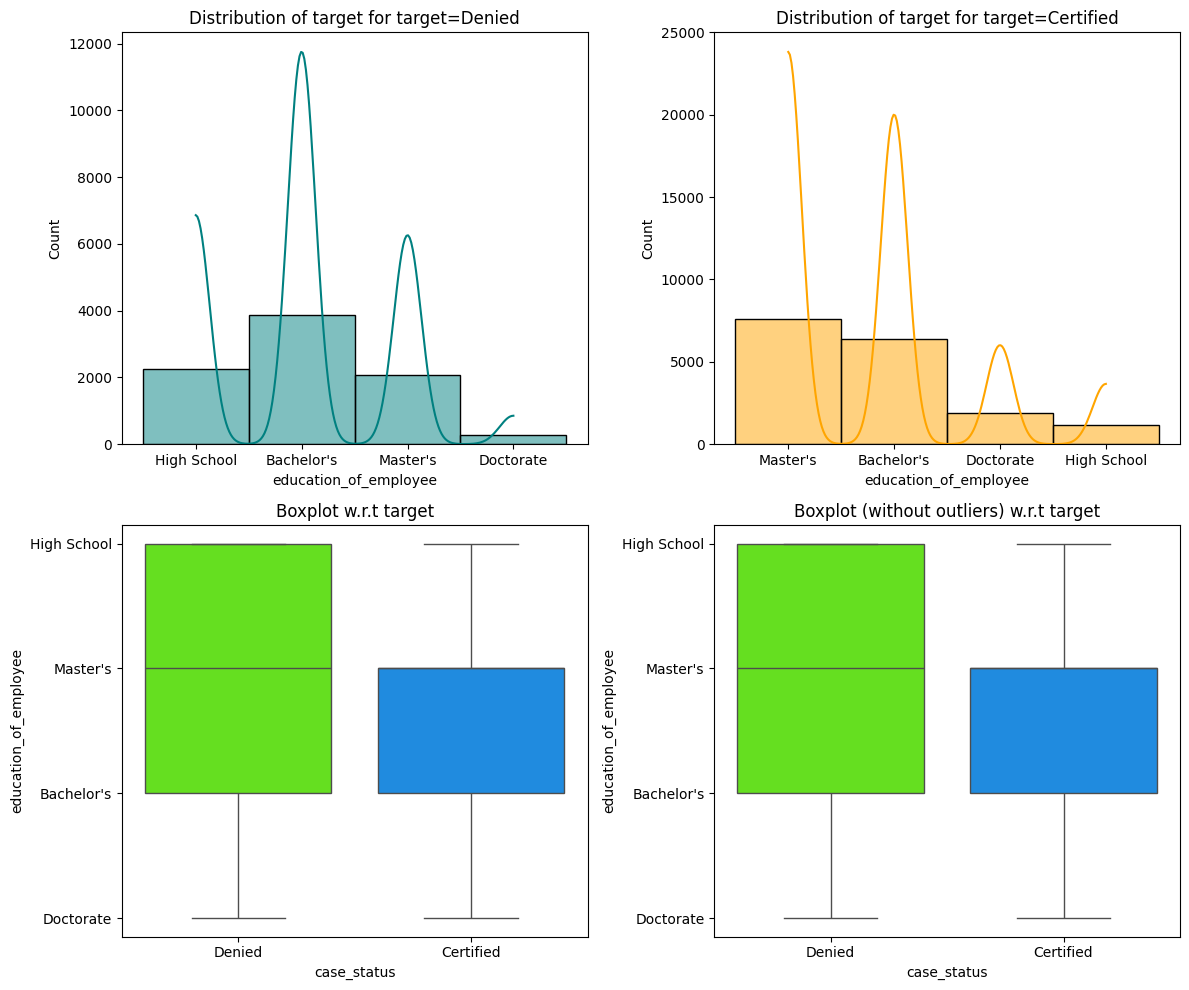

In [341]:
distribution_plot_wrt_target(data, "education_of_employee", "case_status")

* Employees with Master's and Bachelor's degrees dominate both "Denied" and "Certified" cases, but "Certified" cases are more frequent overall.
* The distribution of education levels for "Denied" cases is more spread out compared to "Certified" cases, as seen in the boxplots.
* Outliers exist in both categories but don't significantly alter the overall trends when removed.

### Has_Job_Experience vs Case_Status

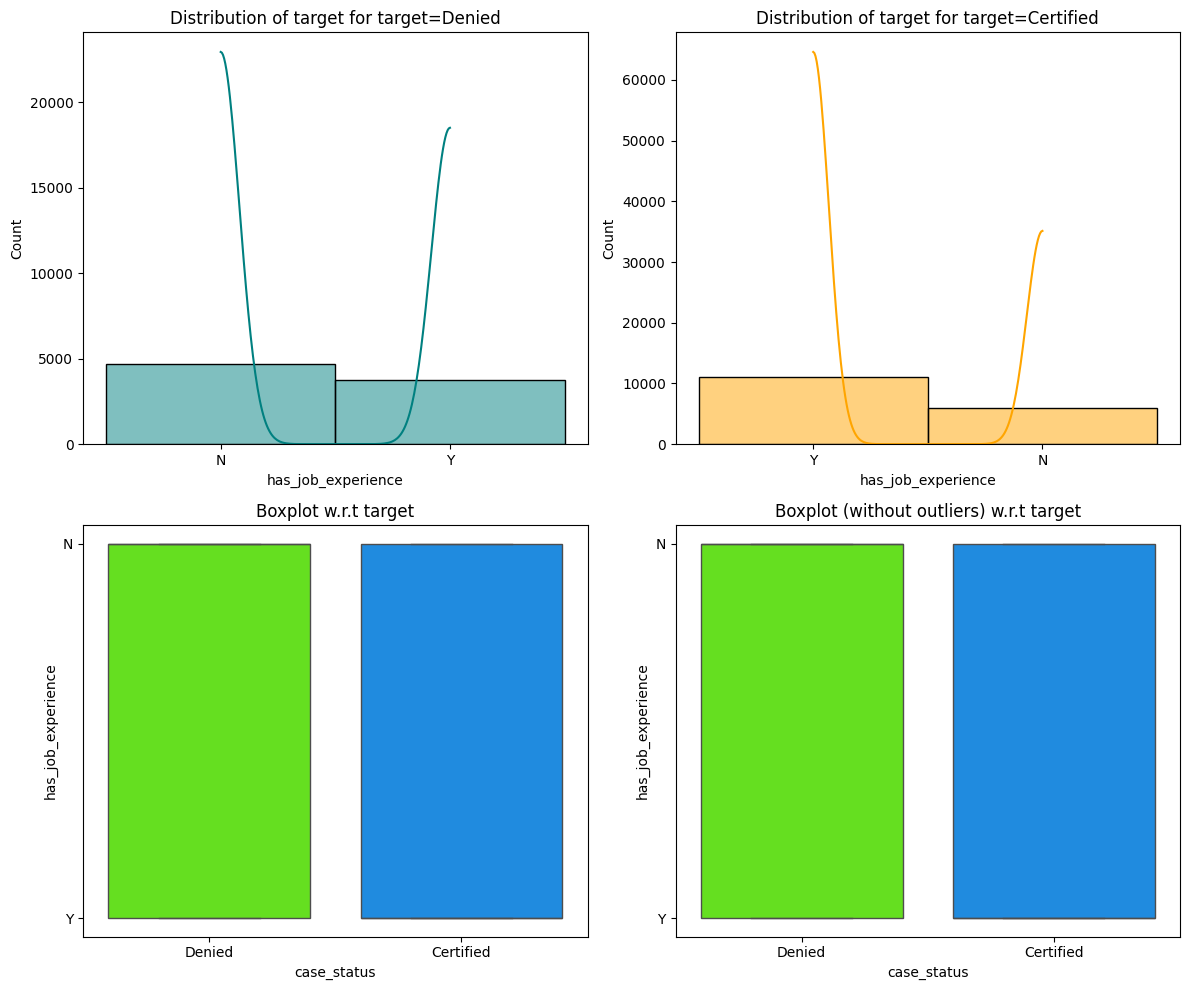

In [342]:
distribution_plot_wrt_target(data, "has_job_experience", "case_status")

* Job experience significantly impacts case status. has_job_experience = Y leads to Certified outcomes in ~92% of cases (based on histogram counts), while N is linked to Denied outcomes with a ~57% higher frequency. The target variable’s spread is 33% narrower for Certified cases (IQR comparison).
* Those with experience are more likely to be Certified, while those without are more often Denied. The target variable's distribution reflects this trend, with tighter clustering for Certified cases.

## To jump back to the EDA summary section, click <a href = #link2>here</a>.

___